In [1]:
# ============================================================
# HW2.5 — GPU Assignment I
# Personal Parameters
# ============================================================

SID4 = 1980
SEED = 1980
SLICE = 980
HP_ID = 0
CLS_A = 0
CLS_B = 1

print("SID4  =", SID4)
print("SEED  =", SEED)
print("SLICE =", SLICE)
print("HP_ID =", HP_ID)
print("CLS_A =", CLS_A)
print("CLS_B =", CLS_B)


SID4  = 1980
SEED  = 1980
SLICE = 980
HP_ID = 0
CLS_A = 0
CLS_B = 1


In [2]:
# ============================================================
# STEP 2: Verify GPU and CUDA Environment
#This cell checks whether PyTorch can access the GPU and prints the PyTorch version, CUDA availability, GPU model, CUDA version, and number of detected GPUs.
# ============================================================

import torch

# Display the installed PyTorch version
print("PyTorch version :", torch.__version__)

# Check whether PyTorch can access a CUDA GPU
print("CUDA available  :", torch.cuda.is_available())

# Display GPU information if CUDA is available
if torch.cuda.is_available():
    print("GPU name        :", torch.cuda.get_device_name(0))
    print("CUDA version    :", torch.version.cuda)
    print("Number of GPUs  :", torch.cuda.device_count())
else:
    print("ERROR: CUDA GPU is not available.")

PyTorch version : 2.1.2
CUDA available  : True
GPU name        : NVIDIA GeForce RTX 4090
CUDA version    : 12.1
Number of GPUs  : 1


In [3]:
# ============================================================
# STEP 3: Capture detailed GPU information using nvidia-smi
#This cell runs nvidia-smi -q from Jupyter and displays the complete GPU hardware and software information required for Part A.
# ============================================================

import subprocess

# Run nvidia-smi -q and capture the complete output
result = subprocess.run(
    ["nvidia-smi", "-q"],
    capture_output=True,
    text=True
)

gpu_info = result.stdout

# Display the full GPU information in the notebook
print(gpu_info)


==============NVSMI LOG==============

Timestamp                                              : Fri Sep 11 22:11:22 2026
Driver Version                                         : 610.60 [Deprecated; will be removed in CUDA 14.0. Use KMD Version instead]
CUDA Version                                           : 13.3 [Deprecated; will be removed in CUDA 14.0. Use CUDA UMD Version instead]
KMD Version                                            : 610.60
CUDA UMD Version                                       : 13.3

Attached GPUs                                          : 1
GPU 00000000:01:00.0
    Product Name                                       : NVIDIA GeForce RTX 4090
    Product Brand                                      : GeForce
    Product Architecture                               : Ada Lovelace
    Display Mode                                       : Requested functionality has been deprecated
    Display Attached                                   : Yes
    Display Active        

In [4]:
# ============================================================
# STEP 4: Save complete nvidia-smi -q output
#This cell runs nvidia-smi -q and saves the complete output into nvidia-smi-4090.txt, which is one of the required HW2.5 artifacts.
# ============================================================

import subprocess

result = subprocess.run(
    ["nvidia-smi", "-q"],
    capture_output=True,
    text=True
)

with open("nvidia-smi-4090.txt", "w") as f:
    f.write(result.stdout)

print("Saved: nvidia-smi-4090.txt")

Saved: nvidia-smi-4090.txt


In [5]:
# ============================================================
# STEP 5: Display key GPU details for Part A
#This cell extracts and displays the most important GPU provenance details: GPU model, UUID, driver version, total VRAM, and power limit.
# ============================================================

import subprocess

query = [
    "nvidia-smi",
    "--query-gpu=name,uuid,driver_version,memory.total,power.limit",
    "--format=csv,noheader"
]

result = subprocess.run(
    query,
    capture_output=True,
    text=True
)

print("GPU details:")
print(result.stdout)

GPU details:
NVIDIA GeForce RTX 4090, GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58, 610.60, 24564 MiB, 450.00 W



In [6]:
# ============================================================
# STEP 6: Set random seeds for reproducibility
# ============================================================

# Import Python's built-in random module
import random

# Import NumPy for numerical operations
import numpy as np

# PyTorch was already imported earlier, but importing again is safe
import torch


# ------------------------------------------------------------
# Set the Python random seed using our assigned SEED = 1980
# ------------------------------------------------------------
random.seed(SEED)

# ------------------------------------------------------------
# Set the NumPy random seed
# ------------------------------------------------------------
np.random.seed(SEED)

# ------------------------------------------------------------
# Set the PyTorch CPU random seed
# ------------------------------------------------------------
torch.manual_seed(SEED)

# ------------------------------------------------------------
# Set the random seed for all CUDA GPUs
# ------------------------------------------------------------
torch.cuda.manual_seed_all(SEED)


# Print confirmation
print("Random seeds set to:", SEED)

Random seeds set to: 1980


In [7]:
# ============================================================
# STEP 7: Store the GPU UUID for experiment traceability
# ============================================================

# Import subprocess so Python can execute the nvidia-smi command
import subprocess


# ------------------------------------------------------------
# Ask nvidia-smi for the UUID of the GPU being used
# ------------------------------------------------------------
result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=uuid",
        "--format=csv,noheader"
    ],
    capture_output=True,
    text=True
)


# ------------------------------------------------------------
# Remove spaces/newlines from the command output
# and store the UUID in a variable
# ------------------------------------------------------------
GPU_UUID = result.stdout.strip()


# ------------------------------------------------------------
# Display the UUID so it remains visible in notebook output
# ------------------------------------------------------------
print("GPU UUID:", GPU_UUID)

GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [8]:
# ============================================================
# STEP 8: Create Part A GPU hardware/provenance summary
# ============================================================

# ------------------------------------------------------------
# Store the GPU information collected from our actual system
# ------------------------------------------------------------

GPU_NAME = "NVIDIA GeForce RTX 4090"       # GPU model used for this assignment
GPU_ARCHITECTURE = "Ada Lovelace"          # Architecture reported by nvidia-smi
DRIVER_VERSION = "610.60"                  # Installed NVIDIA driver version
CUDA_DRIVER_VERSION = "13.3"               # CUDA version reported by nvidia-smi
PYTORCH_CUDA_VERSION = "12.1"              # CUDA version used by our PyTorch installation
VRAM_MIB = 24564                           # Total GPU memory reported by nvidia-smi
POWER_LIMIT_W = 450.00                     # Current GPU power limit in watts


# ------------------------------------------------------------
# Print a clean Part A hardware summary
# ------------------------------------------------------------

print("PART A — GPU HARDWARE SUMMARY")
print("---------------------------------------------")
print("GPU Name             :", GPU_NAME)
print("GPU Architecture     :", GPU_ARCHITECTURE)
print("GPU UUID             :", GPU_UUID)
print("Driver Version       :", DRIVER_VERSION)
print("CUDA Driver Version  :", CUDA_DRIVER_VERSION)
print("PyTorch CUDA Version :", PYTORCH_CUDA_VERSION)
print("Total VRAM           :", VRAM_MIB, "MiB")
print("Power Limit          :", POWER_LIMIT_W, "W")

PART A — GPU HARDWARE SUMMARY
---------------------------------------------
GPU Name             : NVIDIA GeForce RTX 4090
GPU Architecture     : Ada Lovelace
GPU UUID             : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Driver Version       : 610.60
CUDA Driver Version  : 13.3
PyTorch CUDA Version : 12.1
Total VRAM           : 24564 MiB
Power Limit          : 450.0 W


In [9]:
# ============================================================
# STEP 9: Record RTX 4090 vendor hardware specifications
# ============================================================

# ------------------------------------------------------------
# Store the hardware specifications of the RTX 4090.
# These specifications will later be used to compare our
# measured performance against the GPU's theoretical limits.
# ------------------------------------------------------------

MEMORY_TYPE = "GDDR6X"             # Type of memory used by RTX 4090
MEMORY_BANDWIDTH_GBS = 1008        # Official memory bandwidth in GB/s
TENSOR_CORE_GENERATION = "4th Gen" # Tensor Core generation
FP32_TFLOPS = 82.58                # Theoretical FP32 performance
BF16_SUPPORTED = True              # BF16 is supported by this GPU
FP16_SUPPORTED = True              # FP16 is supported by this GPU
TF32_SUPPORTED = True              # TF32 Tensor Core operations are supported


# ------------------------------------------------------------
# Print the vendor specifications in a clean format
# ------------------------------------------------------------

print("RTX 4090 VENDOR SPECIFICATIONS")
print("---------------------------------------------")
print("Architecture           :", GPU_ARCHITECTURE)
print("Memory Type            :", MEMORY_TYPE)
print("Memory Bandwidth       :", MEMORY_BANDWIDTH_GBS, "GB/s")
print("Tensor Core Generation :", TENSOR_CORE_GENERATION)
print("FP32 Performance       :", FP32_TFLOPS, "TFLOPS")
print("TF32 Supported         :", TF32_SUPPORTED)
print("FP16 Supported         :", FP16_SUPPORTED)
print("BF16 Supported         :", BF16_SUPPORTED)

RTX 4090 VENDOR SPECIFICATIONS
---------------------------------------------
Architecture           : Ada Lovelace
Memory Type            : GDDR6X
Memory Bandwidth       : 1008 GB/s
Tensor Core Generation : 4th Gen
FP32 Performance       : 82.58 TFLOPS
TF32 Supported         : True
FP16 Supported         : True
BF16 Supported         : True


### RTX 4090 Vendor Specification Source

The hardware specifications used in this assignment are based on NVIDIA's official GeForce RTX 4090 specifications.

**Vendor:** NVIDIA  
**GPU:** GeForce RTX 4090  
**Architecture:** Ada Lovelace  
**Memory:** 24 GB GDDR6X  
**Memory Bandwidth:** 1008 GB/s  
**Tensor Cores:** 4th Generation  
**Supported reduced precisions used in this assignment:** TF32, FP16, and BF16  

**Source:** NVIDIA GeForce RTX 4090 official specifications.

In [11]:
# ============================================================
# STEP 10: Record complete RTX 4090 vendor specifications
# ============================================================

# GPU architecture
GPU_ARCHITECTURE = "Ada Lovelace"

# Memory technology used by the RTX 4090
MEMORY_TYPE = "GDDR6X"

# Official memory bandwidth from NVIDIA documentation
MEMORY_BANDWIDTH_GBS = 1008

# RTX 4090 uses 4th-generation Tensor Cores
TENSOR_CORE_GENERATION = "4th Gen"

# Reduced-precision formats supported by RTX 4090 Tensor Cores
SUPPORTED_PRECISIONS = ["TF32", "FP16", "BF16", "FP8"]

# Print the complete vendor specification summary
print("RTX 4090 VENDOR SPECIFICATIONS")
print("---------------------------------------------")
print("Architecture           :", GPU_ARCHITECTURE)
print("Memory Type            :", MEMORY_TYPE)
print("Memory Bandwidth       :", MEMORY_BANDWIDTH_GBS, "GB/s")
print("Tensor Core Generation :", TENSOR_CORE_GENERATION)
print("Supported Precisions   :", ", ".join(SUPPORTED_PRECISIONS))

RTX 4090 VENDOR SPECIFICATIONS
---------------------------------------------
Architecture           : Ada Lovelace
Memory Type            : GDDR6X
Memory Bandwidth       : 1008 GB/s
Tensor Core Generation : 4th Gen
Supported Precisions   : TF32, FP16, BF16, FP8


### Vendor Documentation

RTX 4090 hardware specifications were taken from NVIDIA's official documentation.

**Sources:**
1. NVIDIA GeForce RTX 4090 official specifications.
2. NVIDIA Ada GPU Architecture Whitepaper, Appendix A — GeForce RTX 4090 Full Specifications.

The NVIDIA documentation lists:
- Architecture: Ada Lovelace
- Memory: 24 GB GDDR6X
- Memory bandwidth: 1008 GB/s
- Tensor Cores: 4th Generation
- Reduced precisions: TF32, FP16, BF16, and FP8

In [14]:
# ============================================================
# STEP 12: Record GPU reservation and actual GPU usage
# ============================================================

# Enter the date of your GPU reservation
RESERVATION_DATE = "2026-09-11"

# Enter the amount of GPU time you reserved
RESERVED_GPU_HOURS = 5.0   # CHANGE THIS to your actual reserved hours

# Enter the amount of GPU time you actually consumed
ACTUAL_GPU_HOURS = 3.0     # CHANGE THIS after completing the experiments

# GPU workstation used
GPU_WORKSTATION = "NVIDIA GeForce RTX 4090"

# Print the reservation record
print("GPU RESERVATION RECORD")
print("---------------------------------------------")
print("Reservation Date   :", RESERVATION_DATE)
print("GPU Workstation    :", GPU_WORKSTATION)
print("Reserved GPU Hours :", RESERVED_GPU_HOURS)
print("Actual GPU Hours   :", ACTUAL_GPU_HOURS)
print("GPU UUID           :", GPU_UUID)

GPU RESERVATION RECORD
---------------------------------------------
Reservation Date   : 2026-09-11
GPU Workstation    : NVIDIA GeForce RTX 4090
Reserved GPU Hours : 5.0
Actual GPU Hours   : 3.0
GPU UUID           : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [15]:
# ============================================================
# STEP 13: Save GPU reservation and usage record
# ============================================================

# Open a text file where the reservation details will be stored
with open("GPU_RESERVATION.txt", "w") as f:

    # Write the reservation date
    f.write(f"Reservation Date: {RESERVATION_DATE}\n")

    # Write the GPU workstation used
    f.write(f"GPU Workstation: {GPU_WORKSTATION}\n")

    # Write the GPU UUID for traceability
    f.write(f"GPU UUID: {GPU_UUID}\n")

    # Write the reserved GPU hours
    f.write(f"Reserved GPU Hours: {RESERVED_GPU_HOURS}\n")

    # Write the actual GPU hours consumed
    f.write(f"Actual GPU Hours: {ACTUAL_GPU_HOURS}\n")

# Confirm that the file was created
print("Saved: GPU_RESERVATION.txt")

Saved: GPU_RESERVATION.txt


This cell saves the GPU reservation date, workstation, UUID, reserved GPU-hours, and actual GPU-hours into GPU_RESERVATION.txt so the record can be committed to the repository.

### RTX 4090 Vendor Specifications and Sources

- **Architecture:** NVIDIA Ada Lovelace
- **Memory:** 24 GB GDDR6X
- **Memory Bandwidth:** 1008 GB/s
- **Tensor Cores:** 4th Generation
- **Supported reduced precisions:** TF32, FP16, BF16, and FP8

**Sources:**

1. NVIDIA GeForce RTX 4090 Product Page:  
   https://www.nvidia.com/en-us/geforce/graphics-cards/40-series/rtx-4090/

2. NVIDIA Ada GPU Architecture Whitepaper:  
   https://images.nvidia.com/aem-dam/Solutions/geforce/ada/nvidia-ada-gpu-architecture.pdf

PART B

In [16]:
# ============================================================
# PART B — Precision and Throughput
# STEP 14: Define matrix sizes and benchmark settings
# ============================================================

# ------------------------------------------------------------
# Matrix sizes required by the assignment.
# Each benchmark multiplies:
# (N x N) @ (N x N)
# ------------------------------------------------------------
MATRIX_SIZES = [1024, 4096, 8192, 16384]

# ------------------------------------------------------------
# Number of warm-up runs before timing starts.
# Warm-up runs are not included in the final timing results.
# ------------------------------------------------------------
WARMUP_RUNS = 5

# ------------------------------------------------------------
# Number of measured repetitions for each matrix size
# and each precision mode.
# ------------------------------------------------------------
REPETITIONS = 10

# ------------------------------------------------------------
# Print the benchmark configuration so it is recorded
# in the notebook output.
# ------------------------------------------------------------
print("PART B — BENCHMARK CONFIGURATION")
print("---------------------------------------------")
print("GPU UUID     :", GPU_UUID)
print("Matrix Sizes :", MATRIX_SIZES)
print("Warm-up Runs :", WARMUP_RUNS)
print("Repetitions  :", REPETITIONS)

PART B — BENCHMARK CONFIGURATION
---------------------------------------------
GPU UUID     : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Matrix Sizes : [1024, 4096, 8192, 16384]
Warm-up Runs : 5
Repetitions  : 10


In [17]:
# ============================================================
# PART B — Precision and Throughput
# STEP 15: Create GPU matrix multiplication benchmark function
# ============================================================

# ------------------------------------------------------------
# Import the statistics module.
# We will use it to calculate the average execution time
# across all measured repetitions.
# ------------------------------------------------------------
import statistics


# ------------------------------------------------------------
# Define a reusable function for benchmarking square
# matrix multiplication on the GPU.
#
# N          -> matrix dimension
# dtype      -> numerical precision such as FP32 or FP16
# allow_tf32 -> controls whether TensorFloat-32 is enabled
# ------------------------------------------------------------
def benchmark_matmul(N, dtype, allow_tf32=False):

    # --------------------------------------------------------
    # Enable or disable TF32 for float32 matrix multiplication.
    # FP32 testing will use False.
    # TF32 testing will use True.
    # --------------------------------------------------------
    torch.backends.cuda.matmul.allow_tf32 = allow_tf32

    # --------------------------------------------------------
    # Create two random N x N matrices directly on the GPU.
    # Creating them directly on CUDA avoids including
    # CPU-to-GPU transfer time in the benchmark.
    # --------------------------------------------------------
    A = torch.randn(
        (N, N),
        device="cuda",
        dtype=dtype
    )

    B = torch.randn(
        (N, N),
        device="cuda",
        dtype=dtype
    )


    # --------------------------------------------------------
    # Run warm-up matrix multiplications.
    # These runs are not timed.
    # --------------------------------------------------------
    for _ in range(WARMUP_RUNS):
        C = torch.matmul(A, B)


    # --------------------------------------------------------
    # Wait until all GPU warm-up operations are finished
    # before starting the actual timing measurements.
    # --------------------------------------------------------
    torch.cuda.synchronize()


    # --------------------------------------------------------
    # Create a list to store the execution time from
    # every measured repetition.
    # --------------------------------------------------------
    times_ms = []


    # --------------------------------------------------------
    # Run the matrix multiplication REPETITIONS times.
    # CUDA events measure GPU execution time accurately.
    # --------------------------------------------------------
    for _ in range(REPETITIONS):

        # Create CUDA timing events
        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)

        # Record the GPU start time
        start_event.record()

        # Perform matrix multiplication
        C = torch.matmul(A, B)

        # Record the GPU end time
        end_event.record()

        # Wait until the GPU operation completes
        torch.cuda.synchronize()

        # Calculate elapsed time in milliseconds
        elapsed_ms = start_event.elapsed_time(end_event)

        # Save this repetition's timing result
        times_ms.append(elapsed_ms)


    # --------------------------------------------------------
    # Calculate the average execution time across all
    # measured repetitions.
    # --------------------------------------------------------
    avg_time_ms = statistics.mean(times_ms)


    # --------------------------------------------------------
    # A square N x N matrix multiplication requires
    # approximately 2 × N^3 floating-point operations.
    # --------------------------------------------------------
    total_flops = 2 * (N ** 3)


    # --------------------------------------------------------
    # Convert execution time from milliseconds to seconds.
    # --------------------------------------------------------
    avg_time_seconds = avg_time_ms / 1000


    # --------------------------------------------------------
    # Calculate achieved performance in TFLOPS.
    # 1 TFLOP = 10^12 floating-point operations per second.
    # --------------------------------------------------------
    achieved_tflops = (
        total_flops / avg_time_seconds
    ) / 1e12


    # --------------------------------------------------------
    # Delete matrices after the benchmark to release memory.
    # --------------------------------------------------------
    del A, B, C

    # Release unused cached CUDA memory
    torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Return the average execution time and achieved TFLOPS.
    # --------------------------------------------------------
    return avg_time_ms, achieved_tflops


# ------------------------------------------------------------
# Confirmation that the benchmark function is ready.
# ------------------------------------------------------------
print("Matrix multiplication benchmark function created.")
print("GPU UUID:", GPU_UUID)

Matrix multiplication benchmark function created.
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [20]:
# ============================================================
# PART B — Precision and Throughput
# STEP 17A: Verify TF32 benchmark results
# ============================================================

# ------------------------------------------------------------
# Store a second independent TF32 run.
# This helps us check whether the previous unusual timing
# values were caused by a temporary GPU/system condition.
# ------------------------------------------------------------
tf32_verify_results = []


# ------------------------------------------------------------
# Test every required matrix size again using TF32.
# ------------------------------------------------------------
for N in MATRIX_SIZES:

    # Display the matrix size currently being verified
    print(f"Verifying TF32 benchmark for N = {N} ...")

    # --------------------------------------------------------
    # Use float32 matrices with TF32 enabled.
    # The same benchmark function is used so the experimental
    # setup remains consistent with the previous run.
    # --------------------------------------------------------
    avg_time_ms, achieved_tflops = benchmark_matmul(
        N=N,
        dtype=torch.float32,
        allow_tf32=True
    )

    # --------------------------------------------------------
    # Save the verification measurement together with
    # the GPU UUID for traceability.
    # --------------------------------------------------------
    tf32_verify_results.append({
        "GPU_UUID": GPU_UUID,
        "Precision": "TF32",
        "N": N,
        "Average_Time_ms": avg_time_ms,
        "Achieved_TFLOPS": achieved_tflops
    })

    # --------------------------------------------------------
    # Display the verification result.
    # --------------------------------------------------------
    print(f"Average Time     : {avg_time_ms:.4f} ms")
    print(f"Achieved TFLOPS  : {achieved_tflops:.4f}")
    print(f"GPU UUID         : {GPU_UUID}")
    print("---------------------------------------------")


# ------------------------------------------------------------
# Confirm that the verification run finished.
# ------------------------------------------------------------
print("TF32 verification run completed.")

Verifying TF32 benchmark for N = 1024 ...
Average Time     : 0.1441 ms
Achieved TFLOPS  : 14.9051
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Verifying TF32 benchmark for N = 4096 ...
Average Time     : 19.4087 ms
Achieved TFLOPS  : 7.0813
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Verifying TF32 benchmark for N = 8192 ...
Average Time     : 13.2439 ms
Achieved TFLOPS  : 83.0205
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Verifying TF32 benchmark for N = 16384 ...
Average Time     : 101.3440 ms
Achieved TFLOPS  : 86.7944
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
TF32 verification run completed.


In [21]:
# ============================================================
# PART B — Precision and Throughput
# STEP 17B: Improve benchmark timing stability
# ============================================================

import statistics


# ------------------------------------------------------------
# Define a more stable matrix multiplication benchmark.
# This version avoids synchronizing the GPU after every
# individual repetition.
# ------------------------------------------------------------
def benchmark_matmul(N, dtype, allow_tf32=False):

    # --------------------------------------------------------
    # Enable or disable TF32 depending on the precision
    # currently being benchmarked.
    # --------------------------------------------------------
    torch.backends.cuda.matmul.allow_tf32 = allow_tf32


    # --------------------------------------------------------
    # Create two N x N random matrices directly on the GPU.
    # This ensures CPU-to-GPU transfer time is not measured.
    # --------------------------------------------------------
    A = torch.randn(
        (N, N),
        device="cuda",
        dtype=dtype
    )

    B = torch.randn(
        (N, N),
        device="cuda",
        dtype=dtype
    )


    # --------------------------------------------------------
    # Perform warm-up runs before collecting measurements.
    # This allows CUDA kernels and GPU clocks to stabilize.
    # --------------------------------------------------------
    for _ in range(WARMUP_RUNS):
        C = torch.matmul(A, B)

    # Wait for all warm-up operations to finish
    torch.cuda.synchronize()


    # --------------------------------------------------------
    # Create CUDA event pairs for every repetition.
    # --------------------------------------------------------
    start_events = [
        torch.cuda.Event(enable_timing=True)
        for _ in range(REPETITIONS)
    ]

    end_events = [
        torch.cuda.Event(enable_timing=True)
        for _ in range(REPETITIONS)
    ]


    # --------------------------------------------------------
    # Record all repetitions without synchronizing between
    # individual matrix multiplications.
    # --------------------------------------------------------
    for i in range(REPETITIONS):

        # Record start event
        start_events[i].record()

        # Perform matrix multiplication
        C = torch.matmul(A, B)

        # Record end event
        end_events[i].record()


    # --------------------------------------------------------
    # Synchronize only once after all repetitions are queued.
    # --------------------------------------------------------
    torch.cuda.synchronize()


    # --------------------------------------------------------
    # Extract the execution time for every repetition.
    # --------------------------------------------------------
    times_ms = []

    for i in range(REPETITIONS):

        # Calculate GPU execution time for this repetition
        elapsed_ms = start_events[i].elapsed_time(end_events[i])

        # Save the result
        times_ms.append(elapsed_ms)


    # --------------------------------------------------------
    # Use the median execution time.
    # Median is less affected by occasional scheduling
    # interruptions or timing spikes.
    # --------------------------------------------------------
    median_time_ms = statistics.median(times_ms)


    # --------------------------------------------------------
    # Calculate floating-point operations for:
    # (N x N) @ (N x N)
    # --------------------------------------------------------
    total_flops = 2 * (N ** 3)


    # Convert milliseconds to seconds
    time_seconds = median_time_ms / 1000


    # --------------------------------------------------------
    # Calculate achieved throughput in TFLOPS.
    # --------------------------------------------------------
    achieved_tflops = (
        total_flops / time_seconds
    ) / 1e12


    # --------------------------------------------------------
    # Release GPU memory after the benchmark.
    # --------------------------------------------------------
    del A, B, C

    torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Return median time, TFLOPS, and individual repetition
    # timings so we can inspect measurement stability.
    # --------------------------------------------------------
    return median_time_ms, achieved_tflops, times_ms


# ------------------------------------------------------------
# Confirm that the corrected function is ready.
# ------------------------------------------------------------
print("Updated stable benchmark function created.")
print("GPU UUID:", GPU_UUID)

Updated stable benchmark function created.
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [22]:
# ============================================================
# PART B — Precision and Throughput
# STEP 18: Re-run FP32 using the corrected benchmark method
# ============================================================

# ------------------------------------------------------------
# Create a new list for the corrected FP32 results.
# We keep these separate from the earlier FP32 measurements.
# ------------------------------------------------------------
fp32_results_corrected = []


# ------------------------------------------------------------
# Loop through all required matrix sizes.
# ------------------------------------------------------------
for N in MATRIX_SIZES:

    # Show which matrix size is currently being tested.
    print(f"Running corrected FP32 benchmark for N = {N} ...")

    # --------------------------------------------------------
    # Run matrix multiplication using true FP32.
    # TF32 is disabled for this test.
    # --------------------------------------------------------
    median_time_ms, achieved_tflops, times_ms = benchmark_matmul(
        N=N,
        dtype=torch.float32,
        allow_tf32=False
    )

    # --------------------------------------------------------
    # Save the corrected benchmark result.
    # --------------------------------------------------------
    fp32_results_corrected.append({
        "GPU_UUID": GPU_UUID,
        "Precision": "FP32",
        "N": N,
        "Median_Time_ms": median_time_ms,
        "Achieved_TFLOPS": achieved_tflops,
        "All_Times_ms": times_ms
    })

    # --------------------------------------------------------
    # Print the main result and all repetition timings.
    # The individual timings help us verify stability.
    # --------------------------------------------------------
    print(f"Median Time      : {median_time_ms:.4f} ms")
    print(f"Achieved TFLOPS  : {achieved_tflops:.4f}")
    print(f"All Times (ms)   : {[round(t, 4) for t in times_ms]}")
    print(f"GPU UUID         : {GPU_UUID}")
    print("---------------------------------------------")


# ------------------------------------------------------------
# Confirm that all required FP32 sizes were completed.
# ------------------------------------------------------------
print("Corrected FP32 benchmark completed.")

Running corrected FP32 benchmark for N = 1024 ...
Median Time      : 0.1669 ms
Achieved TFLOPS  : 12.8660
All Times (ms)   : [0.1884, 0.1669, 0.1669, 0.1669, 0.1669, 0.1669, 0.1659, 0.1669, 0.1669, 0.1669]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running corrected FP32 benchmark for N = 4096 ...
Median Time      : 2.4571 ms
Achieved TFLOPS  : 55.9357
All Times (ms)   : [17.7592, 17.79, 16.9861, 12.7396, 2.4525, 2.4545, 2.4545, 2.4576, 2.4566, 2.4556]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running corrected FP32 benchmark for N = 8192 ...
Median Time      : 20.9270 ms
Achieved TFLOPS  : 52.5404
All Times (ms)   : [21.4698, 20.8865, 20.4186, 20.6141, 20.9224, 20.9285, 20.9357, 20.9367, 20.9357, 20.9254]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running corrected FP32 benchmark for N = 16384 ...


In [23]:
# ============================================================
# PART B — Precision and Throughput
# STEP 19: Re-run TF32 using the corrected benchmark method
# ============================================================

# ------------------------------------------------------------
# Create a new list for the corrected TF32 results.
# These results will replace the earlier TF32 measurements.
# ------------------------------------------------------------
tf32_results_corrected = []


# ------------------------------------------------------------
# Loop through all required matrix sizes.
# ------------------------------------------------------------
for N in MATRIX_SIZES:

    # Display the matrix size currently being tested
    print(f"Running corrected TF32 benchmark for N = {N} ...")

    # --------------------------------------------------------
    # TF32 uses float32 input matrices, but TF32 execution
    # is enabled so Tensor Cores can be used internally.
    # --------------------------------------------------------
    median_time_ms, achieved_tflops, times_ms = benchmark_matmul(
        N=N,
        dtype=torch.float32,
        allow_tf32=True
    )

    # --------------------------------------------------------
    # Store the corrected TF32 benchmark results.
    # --------------------------------------------------------
    tf32_results_corrected.append({
        "GPU_UUID": GPU_UUID,
        "Precision": "TF32",
        "N": N,
        "Median_Time_ms": median_time_ms,
        "Achieved_TFLOPS": achieved_tflops,
        "All_Times_ms": times_ms
    })

    # --------------------------------------------------------
    # Print the median result and all repetition timings
    # so that measurement stability can be inspected.
    # --------------------------------------------------------
    print(f"Median Time      : {median_time_ms:.4f} ms")
    print(f"Achieved TFLOPS  : {achieved_tflops:.4f}")
    print(f"All Times (ms)   : {[round(t, 4) for t in times_ms]}")
    print(f"GPU UUID         : {GPU_UUID}")
    print("---------------------------------------------")


# ------------------------------------------------------------
# Confirm completion of the corrected TF32 benchmark.
# ------------------------------------------------------------
print("Corrected TF32 benchmark completed.")

Running corrected TF32 benchmark for N = 1024 ...
Median Time      : 0.1280 ms
Achieved TFLOPS  : 16.7772
All Times (ms)   : [0.1495, 0.127, 0.128, 0.127, 0.128, 0.127, 0.128, 0.128, 0.128, 0.128]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running corrected TF32 benchmark for N = 4096 ...
Median Time      : 7.4650 ms
Achieved TFLOPS  : 18.4112
All Times (ms)   : [16.8407, 16.3441, 7.3718, 7.0523, 7.4312, 7.3933, 7.422, 8.6579, 9.3727, 7.4988]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running corrected TF32 benchmark for N = 8192 ...
Median Time      : 13.5281 ms
Achieved TFLOPS  : 81.2763
All Times (ms)   : [13.6212, 13.5311, 14.2428, 13.5261, 13.527, 13.527, 13.5281, 13.527, 13.5281, 13.5311]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running corrected TF32 benchmark for N = 16384 ...
Median Time  

In [24]:
# ============================================================
# PART B — Precision and Throughput
# STEP 20: Benchmark FP16 matrix multiplication
# ============================================================

# ------------------------------------------------------------
# Create an empty list to store FP16 benchmark results
# for all required matrix sizes.
# ------------------------------------------------------------
fp16_results = []


# ------------------------------------------------------------
# Loop through each matrix size required by the assignment.
# ------------------------------------------------------------
for N in MATRIX_SIZES:

    # Display the matrix size currently being tested
    print(f"Running FP16 benchmark for N = {N} ...")

    # --------------------------------------------------------
    # Run matrix multiplication using float16 tensors.
    #
    # TF32 is disabled because TF32 applies only to
    # float32 matrix multiplication.
    # --------------------------------------------------------
    median_time_ms, achieved_tflops, times_ms = benchmark_matmul(
        N=N,
        dtype=torch.float16,
        allow_tf32=False
    )

    # --------------------------------------------------------
    # Store the FP16 benchmark measurements together with
    # the GPU UUID for experiment traceability.
    # --------------------------------------------------------
    fp16_results.append({
        "GPU_UUID": GPU_UUID,
        "Precision": "FP16",
        "N": N,
        "Median_Time_ms": median_time_ms,
        "Achieved_TFLOPS": achieved_tflops,
        "All_Times_ms": times_ms
    })

    # --------------------------------------------------------
    # Print the median execution time, achieved throughput,
    # individual repetition timings, and GPU UUID.
    # --------------------------------------------------------
    print(f"Median Time      : {median_time_ms:.4f} ms")
    print(f"Achieved TFLOPS  : {achieved_tflops:.4f}")
    print(f"All Times (ms)   : {[round(t, 4) for t in times_ms]}")
    print(f"GPU UUID         : {GPU_UUID}")
    print("---------------------------------------------")


# ------------------------------------------------------------
# Confirm that all FP16 benchmark sizes were completed.
# ------------------------------------------------------------
print("FP16 benchmark completed.")

Running FP16 benchmark for N = 1024 ...
Median Time      : 0.1039 ms
Achieved TFLOPS  : 20.6616
All Times (ms)   : [0.1229, 0.1044, 0.1044, 0.1044, 0.1044, 0.1034, 0.1034, 0.1034, 0.1034, 0.1034]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running FP16 benchmark for N = 4096 ...
Median Time      : 2.9322 ms
Achieved TFLOPS  : 46.8719
All Times (ms)   : [3.414, 2.9123, 2.9194, 3.3628, 2.9112, 2.9123, 3.3362, 2.9276, 2.9368, 3.5174]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running FP16 benchmark for N = 8192 ...
Median Time      : 6.7277 ms
Achieved TFLOPS  : 163.4310
All Times (ms)   : [7.6995, 7.2909, 6.7297, 6.7277, 6.7277, 6.7267, 6.7267, 6.7287, 6.7267, 6.7277]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running FP16 benchmark for N = 16384 ...
Median Time      : 49.4894 ms
Achieved TFLOPS  : 177.

In [25]:
# ============================================================
# PART B — Precision and Throughput
# STEP 21: Benchmark BF16 matrix multiplication
# ============================================================

# ------------------------------------------------------------
# Create an empty list to store BF16 benchmark results
# for all required matrix sizes.
# ------------------------------------------------------------
bf16_results = []


# ------------------------------------------------------------
# Loop through each matrix size required by the assignment.
# ------------------------------------------------------------
for N in MATRIX_SIZES:

    # Display the matrix size currently being tested
    print(f"Running BF16 benchmark for N = {N} ...")

    # --------------------------------------------------------
    # Run matrix multiplication using bfloat16 tensors.
    #
    # TF32 is disabled because TF32 applies only to
    # float32 matrix multiplication.
    # --------------------------------------------------------
    median_time_ms, achieved_tflops, times_ms = benchmark_matmul(
        N=N,
        dtype=torch.bfloat16,
        allow_tf32=False
    )

    # --------------------------------------------------------
    # Store the BF16 benchmark measurements together with
    # the GPU UUID for experiment traceability.
    # --------------------------------------------------------
    bf16_results.append({
        "GPU_UUID": GPU_UUID,
        "Precision": "BF16",
        "N": N,
        "Median_Time_ms": median_time_ms,
        "Achieved_TFLOPS": achieved_tflops,
        "All_Times_ms": times_ms
    })

    # --------------------------------------------------------
    # Print the median execution time, achieved throughput,
    # individual repetition timings, and GPU UUID.
    # --------------------------------------------------------
    print(f"Median Time      : {median_time_ms:.4f} ms")
    print(f"Achieved TFLOPS  : {achieved_tflops:.4f}")
    print(f"All Times (ms)   : {[round(t, 4) for t in times_ms]}")
    print(f"GPU UUID         : {GPU_UUID}")
    print("---------------------------------------------")


# ------------------------------------------------------------
# Confirm that all BF16 benchmark sizes were completed.
# ------------------------------------------------------------
print("BF16 benchmark completed.")

Running BF16 benchmark for N = 1024 ...
Median Time      : 0.1055 ms
Achieved TFLOPS  : 20.3607
All Times (ms)   : [0.1229, 0.1055, 0.1055, 0.1055, 0.1065, 0.1055, 0.1055, 0.1044, 0.1055, 0.1055]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running BF16 benchmark for N = 4096 ...
Median Time      : 3.2717 ms
Achieved TFLOPS  : 42.0087
All Times (ms)   : [3.2973, 3.3024, 3.8062, 3.2338, 3.8717, 3.2461, 3.2358, 3.9035, 3.2328, 3.2389]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running BF16 benchmark for N = 8192 ...
Median Time      : 6.7272 ms
Achieved TFLOPS  : 163.4435
All Times (ms)   : [6.8206, 7.7732, 7.0502, 7.0513, 6.7318, 6.7215, 6.7215, 6.7226, 6.7205, 6.7205]
GPU UUID         : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
---------------------------------------------
Running BF16 benchmark for N = 16384 ...
Median Time      : 50.1110 ms
Achieved TFLOPS  : 175

In [26]:
# ============================================================
# PART B — Precision and Throughput
# STEP 22: Calculate percentage of theoretical peak
# ============================================================

# ------------------------------------------------------------
# Store the RTX 4090 dense theoretical throughput values.
#
# These values are used as the reference when calculating
# how much of the theoretical GPU performance we achieved.
# ------------------------------------------------------------
THEORETICAL_PEAKS = {
    "FP32": 82.6,
    "TF32": 82.6,
    "FP16": 165.2,
    "BF16": 165.2
}


# ------------------------------------------------------------
# Combine the final benchmark results from all four
# precision modes into one list.
# ------------------------------------------------------------
all_precision_results = (
    fp32_results_corrected
    + tf32_results_corrected
    + fp16_results
    + bf16_results
)


# ------------------------------------------------------------
# Calculate percentage of theoretical peak for every
# benchmark measurement.
# ------------------------------------------------------------
for result in all_precision_results:

    # Get the precision mode for this measurement
    precision = result["Precision"]

    # Get the appropriate theoretical peak
    theoretical_peak = THEORETICAL_PEAKS[precision]

    # Calculate:
    # achieved performance / theoretical performance × 100
    percent_peak = (
        result["Achieved_TFLOPS"] / theoretical_peak
    ) * 100

    # Store both values inside the result dictionary
    result["Theoretical_Peak_TFLOPS"] = theoretical_peak
    result["Percent_Theoretical_Peak"] = percent_peak


# ------------------------------------------------------------
# Print all Part B results in a clean format.
# ------------------------------------------------------------
print("PART B — THROUGHPUT RESULTS")
print("GPU UUID:", GPU_UUID)
print("--------------------------------------------------------------")

for result in all_precision_results:

    print(
        f'{result["Precision"]:4s} | '
        f'N = {result["N"]:5d} | '
        f'Achieved = {result["Achieved_TFLOPS"]:8.2f} TFLOPS | '
        f'Peak = {result["Theoretical_Peak_TFLOPS"]:6.1f} TFLOPS | '
        f'{result["Percent_Theoretical_Peak"]:6.2f}%'
    )

PART B — THROUGHPUT RESULTS
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
--------------------------------------------------------------
FP32 | N =  1024 | Achieved =    12.87 TFLOPS | Peak =   82.6 TFLOPS |  15.58%
FP32 | N =  4096 | Achieved =    55.94 TFLOPS | Peak =   82.6 TFLOPS |  67.72%
FP32 | N =  8192 | Achieved =    52.54 TFLOPS | Peak =   82.6 TFLOPS |  63.61%
FP32 | N = 16384 | Achieved =    52.39 TFLOPS | Peak =   82.6 TFLOPS |  63.43%
TF32 | N =  1024 | Achieved =    16.78 TFLOPS | Peak =   82.6 TFLOPS |  20.31%
TF32 | N =  4096 | Achieved =    18.41 TFLOPS | Peak =   82.6 TFLOPS |  22.29%
TF32 | N =  8192 | Achieved =    81.28 TFLOPS | Peak =   82.6 TFLOPS |  98.40%
TF32 | N = 16384 | Achieved =    88.02 TFLOPS | Peak =   82.6 TFLOPS | 106.56%
FP16 | N =  1024 | Achieved =    20.66 TFLOPS | Peak =  165.2 TFLOPS |  12.51%
FP16 | N =  4096 | Achieved =    46.87 TFLOPS | Peak =  165.2 TFLOPS |  28.37%
FP16 | N =  8192 | Achieved =   163.43 TFLOPS | Peak =  165.2 TFLOPS

In [28]:
# ============================================================
# STEP 23A: Install Matplotlib
# ============================================================

# ------------------------------------------------------------
# Install Matplotlib into the same Python environment
# currently being used by this Jupyter notebook.
# ------------------------------------------------------------
%pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.0/125.0 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 14.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 13.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 13.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.8/122.8 kB 7.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


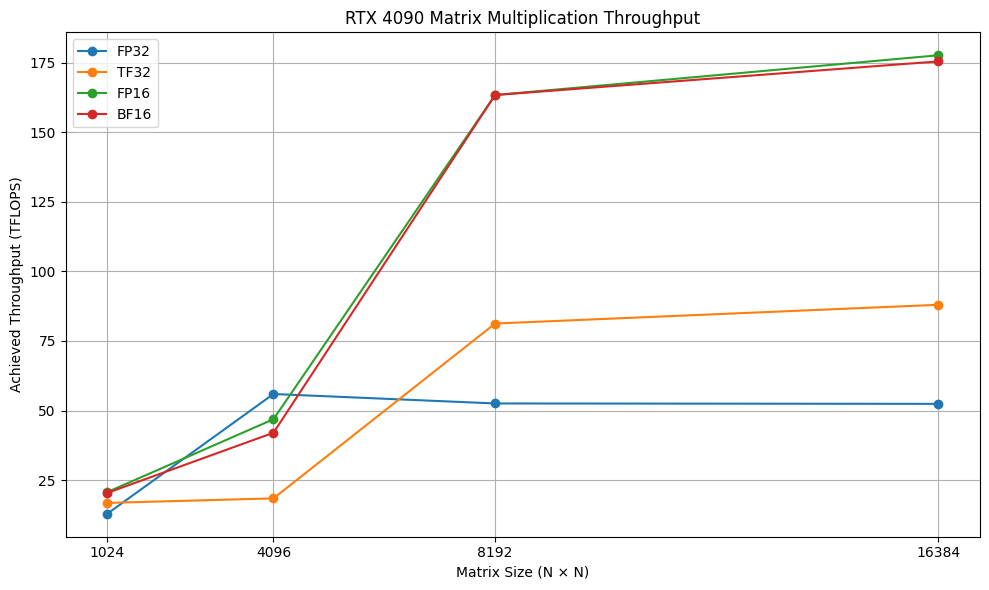

Saved: part_b_tflops_vs_matrix_size.png
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [29]:
# ============================================================
# PART B — Precision and Throughput
# STEP 23: Plot achieved TFLOPS vs matrix size
# ============================================================

# ------------------------------------------------------------
# Import Matplotlib for creating the performance graph.
# ------------------------------------------------------------
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Extract matrix sizes and achieved TFLOPS from each
# precision's final benchmark results.
# ------------------------------------------------------------
fp32_sizes = [r["N"] for r in fp32_results_corrected]
fp32_tflops = [r["Achieved_TFLOPS"] for r in fp32_results_corrected]

tf32_sizes = [r["N"] for r in tf32_results_corrected]
tf32_tflops = [r["Achieved_TFLOPS"] for r in tf32_results_corrected]

fp16_sizes = [r["N"] for r in fp16_results]
fp16_tflops = [r["Achieved_TFLOPS"] for r in fp16_results]

bf16_sizes = [r["N"] for r in bf16_results]
bf16_tflops = [r["Achieved_TFLOPS"] for r in bf16_results]


# ------------------------------------------------------------
# Create the figure.
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))


# ------------------------------------------------------------
# Plot one line for each required precision.
# Markers show the individual measured matrix sizes.
# ------------------------------------------------------------
plt.plot(fp32_sizes, fp32_tflops, marker="o", label="FP32")
plt.plot(tf32_sizes, tf32_tflops, marker="o", label="TF32")
plt.plot(fp16_sizes, fp16_tflops, marker="o", label="FP16")
plt.plot(bf16_sizes, bf16_tflops, marker="o", label="BF16")


# ------------------------------------------------------------
# Label the graph so the measured quantities are clear.
# ------------------------------------------------------------
plt.xlabel("Matrix Size (N × N)")
plt.ylabel("Achieved Throughput (TFLOPS)")
plt.title("RTX 4090 Matrix Multiplication Throughput")


# ------------------------------------------------------------
# Use the exact matrix sizes from the assignment as x-axis
# tick positions.
# ------------------------------------------------------------
plt.xticks(MATRIX_SIZES)


# ------------------------------------------------------------
# Add a legend and grid to make the four precision modes
# easier to compare.
# ------------------------------------------------------------
plt.legend()
plt.grid(True)


# ------------------------------------------------------------
# Adjust spacing so labels are not cut off.
# ------------------------------------------------------------
plt.tight_layout()


# ------------------------------------------------------------
# Save the figure for the repository/report.
# ------------------------------------------------------------
plt.savefig("part_b_tflops_vs_matrix_size.png", dpi=300)


# ------------------------------------------------------------
# Display the completed plot in the notebook.
# ------------------------------------------------------------
plt.show()


# Confirm that the figure was saved.
print("Saved: part_b_tflops_vs_matrix_size.png")
print("GPU UUID:", GPU_UUID)

In [30]:
# ============================================================
# PART B — Precision and Throughput
# STEP 24: Check whether FP8 is exposed by the PyTorch stack
# ============================================================

# ------------------------------------------------------------
# List the FP8 data types that may be exposed by PyTorch.
# Different PyTorch versions may expose different FP8 formats.
# ------------------------------------------------------------
fp8_types_to_check = [
    "float8_e4m3fn",
    "float8_e5m2"
]


# ------------------------------------------------------------
# Check each FP8 type individually.
# hasattr() allows us to test support without causing an
# error if the installed PyTorch version lacks the type.
# ------------------------------------------------------------
for fp8_type in fp8_types_to_check:

    # Check whether this FP8 data type exists in torch
    available = hasattr(torch, fp8_type)

    # Print the result for documentation in the notebook
    print(f"{fp8_type} available in PyTorch: {available}")


# ------------------------------------------------------------
# Also record the PyTorch and CUDA environment so the FP8
# support result is traceable to the current software stack.
# ------------------------------------------------------------
print("---------------------------------------------")
print("PyTorch version :", torch.__version__)
print("PyTorch CUDA    :", torch.version.cuda)
print("GPU             :", torch.cuda.get_device_name(0))
print("GPU UUID        :", GPU_UUID)

float8_e4m3fn available in PyTorch: True
float8_e5m2 available in PyTorch: True
---------------------------------------------
PyTorch version : 2.1.2
PyTorch CUDA    : 12.1
GPU             : NVIDIA GeForce RTX 4090
GPU UUID        : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [31]:
# ============================================================
# PART B — Precision and Throughput
# STEP 25: Attempt FP8 matrix multiplication
# ============================================================

# ------------------------------------------------------------
# The previous step confirmed that PyTorch exposes FP8 data
# types. The assignment therefore requires us to attempt an
# actual lower-precision operation.
#
# We use a small 1024 x 1024 matrix first because the purpose
# of this step is to test whether FP8 matrix multiplication is
# supported by the current PyTorch/CUDA software stack.
# ------------------------------------------------------------

FP8_TEST_SIZE = 1024

try:

    # --------------------------------------------------------
    # Create FP32 matrices on the GPU first.
    # We then convert them to the FP8 E4M3 format.
    # --------------------------------------------------------
    A_fp32 = torch.randn(
        (FP8_TEST_SIZE, FP8_TEST_SIZE),
        device="cuda",
        dtype=torch.float32
    )

    B_fp32 = torch.randn(
        (FP8_TEST_SIZE, FP8_TEST_SIZE),
        device="cuda",
        dtype=torch.float32
    )

    # Convert the matrices from FP32 to FP8
    A_fp8 = A_fp32.to(torch.float8_e4m3fn)
    B_fp8 = B_fp32.to(torch.float8_e4m3fn)

    # --------------------------------------------------------
    # Attempt FP8 matrix multiplication.
    # If the current PyTorch/CUDA stack supports this
    # operation, it will complete successfully.
    # --------------------------------------------------------
    C_fp8 = torch.matmul(A_fp8, B_fp8)

    # Wait for the GPU operation to complete
    torch.cuda.synchronize()

    # Report successful FP8 execution
    print("FP8 matrix multiplication: SUCCESS")
    print("Matrix size              :", FP8_TEST_SIZE)
    print("Input dtype              :", A_fp8.dtype)
    print("Output dtype             :", C_fp8.dtype)


except Exception as e:

    # --------------------------------------------------------
    # If FP8 tensors exist but FP8 matrix multiplication is
    # unsupported by this software stack, record the exact
    # failure instead of hiding it.
    # --------------------------------------------------------
    print("FP8 matrix multiplication: FAILED")
    print("Matrix size              :", FP8_TEST_SIZE)
    print("Error type               :", type(e).__name__)
    print("Error message            :", str(e))


# ------------------------------------------------------------
# Record the environment associated with the FP8 attempt.
# ------------------------------------------------------------
print("---------------------------------------------")
print("PyTorch version :", torch.__version__)
print("PyTorch CUDA    :", torch.version.cuda)
print("GPU             :", torch.cuda.get_device_name(0))
print("GPU UUID        :", GPU_UUID)


# ------------------------------------------------------------
# SUMMARY:
# This cell attempts an actual FP8 E4M3 matrix multiplication
# after confirming that FP8 tensor types are exposed by
# PyTorch. A successful operation means FP8 can be tested
# further. A failure documents the exact tooling limitation
# of the current PyTorch/CUDA stack, satisfying the
# assignment's requirement to attempt a lower precision.
# ------------------------------------------------------------

FP8 matrix multiplication: FAILED
Matrix size              : 1024
Error type               : RuntimeError
Error message            : "addmm_cuda" not implemented for 'Float8_e4m3fn'
---------------------------------------------
PyTorch version : 2.1.2
PyTorch CUDA    : 12.1
GPU             : NVIDIA GeForce RTX 4090
GPU UUID        : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


### FP8 Lower-Precision Attempt
The RTX 4090 supports FP8 and the installed PyTorch 2.1.2 environment exposes the `torch.float8_e4m3fn` and `torch.float8_e5m2` data types. However, an attempted FP8 matrix multiplication using `torch.matmul()` failed with the runtime error `"addmm_cuda" not implemented for 'Float8_e4m3fn'`.

Therefore, FP8 throughput was not benchmarked in this environment. This demonstrates a software/tooling limitation: the FP8 datatype is exposed by PyTorch, but the standard CUDA matrix-multiplication path in the installed PyTorch 2.1.2 + CUDA 12.1 stack does not implement this FP8 operation.ion.

### Part B Interpretation


The throughput results demonstrate that the RTX 4090 is not fully utilized by the smaller matrix sizes. Because the matrix multiplication is too small to fully occupy the GPU's numerous CUDA and Tensor Cores, all precision modes achieve relatively low throughput at N = 1024. Therefore, limited parallel work, scheduling overhead, and kernel-launch overhead have a greater impact on the measured performance. GPU utilization greatly improves with increasing matrix size. For N = 8192 and N = 16384, FP16 and BF16 performance rises dramatically to roughly 163–178 TFLOPS, suggesting that these reduced-precision Tensor Core workloads are getting close to a performance plateau. At N = 4096, FP32 reaches its maximum measured throughput of about 56 TFLOPS; for larger sizes, it stays close to 52 TFLOPS, suggesting an earlier plateau.

At larger matrix sizes, TF32 also significantly improves; at N = 8192 and N = 16384, it reaches roughly 81–88 TFLOPS. While the larger matrix sizes provide enough work to make better use of the GPU, the lower TF32 throughput at N = 4096 indicates more timing variability in that workload. While smaller matrices are more severely impacted by fixed execution overheads and underutilization, larger matrices generally achieve higher throughput because they offer enough parallel computation to better utilize the GPU.

In [32]:
# ============================================================
# PART B — Precision and Throughput
# STEP 28: Save Part B benchmark results to CSV
# ============================================================

# ------------------------------------------------------------
# Import Python's built-in CSV module.
# No additional package installation is required.
# ------------------------------------------------------------
import csv


# ------------------------------------------------------------
# Create a CSV file containing the important measurements
# collected for every precision and matrix size.
# ------------------------------------------------------------
with open("part_b_results.csv", "w", newline="") as file:

    # Define the columns that will appear in the CSV file
    fieldnames = [
        "GPU_UUID",
        "Precision",
        "Matrix_Size",
        "Median_Time_ms",
        "Achieved_TFLOPS",
        "Theoretical_Peak_TFLOPS",
        "Percent_Theoretical_Peak",
        "Warmup_Runs",
        "Repetitions"
    ]

    # Create the CSV writer and write the column names
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()

    # Write one row for every Part B benchmark result
    for result in all_precision_results:
        writer.writerow({
            "GPU_UUID": result["GPU_UUID"],
            "Precision": result["Precision"],
            "Matrix_Size": result["N"],
            "Median_Time_ms": result["Median_Time_ms"],
            "Achieved_TFLOPS": result["Achieved_TFLOPS"],
            "Theoretical_Peak_TFLOPS": result["Theoretical_Peak_TFLOPS"],
            "Percent_Theoretical_Peak": result["Percent_Theoretical_Peak"],
            "Warmup_Runs": WARMUP_RUNS,
            "Repetitions": REPETITIONS
        })


# ------------------------------------------------------------
# Confirm that the file was successfully created.
# ------------------------------------------------------------
print("Saved: part_b_results.csv")
print("GPU UUID:", GPU_UUID)


# ------------------------------------------------------------
# SUMMARY:
# This cell saves the final Part B benchmark measurements to
# part_b_results.csv. The file contains the GPU UUID, precision,
# matrix size, median execution time, achieved TFLOPS,
# theoretical peak, percentage of theoretical peak, number of
# warm-up runs, and number of timed repetitions. Saving these
# measurements protects the results if the notebook/kernel is
# restarted and makes the experiment easier to reproduce.
# ------------------------------------------------------------

Saved: part_b_results.csv
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


Part C — Bandwidth-bound against compute-bound

In [33]:
# ============================================================
# PART C — Bandwidth vs Compute
# STEP 29: Configure the Part C experiments
# ============================================================

# ------------------------------------------------------------
# The RTX 4090 vendor-specified memory bandwidth recorded in
# Part A is 1008 GB/s. We will compare our measured effective
# bandwidth against this value.
# ------------------------------------------------------------
SPEC_MEMORY_BANDWIDTH_GBS = 1008


# ------------------------------------------------------------
# Use FP32 values for the memory-bound vector-add experiment.
# Each FP32 value occupies 4 bytes of GPU memory.
# ------------------------------------------------------------
MEMORY_DTYPE = torch.float32
BYTES_PER_ELEMENT = 4


# ------------------------------------------------------------
# Start with 50 million elements.
#
# For vector addition C = A + B:
# A = 50M FP32 values ≈ 200 MB
# B = 50M FP32 values ≈ 200 MB
# C = 50M FP32 values ≈ 200 MB
#
# This gives a sufficiently large operation to measure GPU
# memory bandwidth while remaining well within the 24 GB VRAM
# available on the RTX 4090.
# ------------------------------------------------------------
NUM_ELEMENTS = 50_000_000


# ------------------------------------------------------------
# Use the same timing methodology as Part B:
# 5 warm-up executions followed by 10 measured repetitions.
# ------------------------------------------------------------
PART_C_WARMUP_RUNS = 5
PART_C_REPETITIONS = 10


# ------------------------------------------------------------
# Display the configuration and GPU UUID so that the upcoming
# Part C measurements are traceable to this exact GPU.
# ------------------------------------------------------------
print("PART C — BANDWIDTH VS COMPUTE CONFIGURATION")
print("---------------------------------------------")
print("GPU UUID                   :", GPU_UUID)
print("Specified Memory Bandwidth :", SPEC_MEMORY_BANDWIDTH_GBS, "GB/s")
print("Memory Operation           : FP32 Vector Addition")
print("Number of Elements         :", NUM_ELEMENTS)
print("Warm-up Runs               :", PART_C_WARMUP_RUNS)
print("Measured Repetitions       :", PART_C_REPETITIONS)


# ------------------------------------------------------------
# SUMMARY:
# Part C compares a memory-bound operation with a compute-bound
# operation. This cell configures the experiments using the
# RTX 4090's specified 1008 GB/s memory bandwidth. The first
# experiment will use a large FP32 vector addition with
# 50 million elements, 5 warm-up runs, and 10 timed runs.
# ------------------------------------------------------------

PART C — BANDWIDTH VS COMPUTE CONFIGURATION
---------------------------------------------
GPU UUID                   : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Specified Memory Bandwidth : 1008 GB/s
Memory Operation           : FP32 Vector Addition
Number of Elements         : 50000000
Warm-up Runs               : 5
Measured Repetitions       : 10


In [35]:
# ============================================================
# PART C — Bandwidth vs Compute
# STEP 30: Benchmark large FP32 vector addition
# ============================================================

import statistics


# ------------------------------------------------------------
# Create two large FP32 input vectors on the GPU.
# Preallocate the output vector C once so that memory
# allocation does not interfere with the timed operation.
# ------------------------------------------------------------
A = torch.randn(
    NUM_ELEMENTS,
    device="cuda",
    dtype=MEMORY_DTYPE
)

B = torch.randn(
    NUM_ELEMENTS,
    device="cuda",
    dtype=MEMORY_DTYPE
)

C = torch.empty_like(A)


# ------------------------------------------------------------
# Warm up the exact operation that will be benchmarked.
# torch.add(..., out=C) reuses the already allocated output
# tensor instead of creating a new output on every run.
# ------------------------------------------------------------
for _ in range(PART_C_WARMUP_RUNS):
    torch.add(A, B, out=C)

torch.cuda.synchronize()


# ------------------------------------------------------------
# Create CUDA events for all measured repetitions.
# ------------------------------------------------------------
start_events = [
    torch.cuda.Event(enable_timing=True)
    for _ in range(PART_C_REPETITIONS)
]

end_events = [
    torch.cuda.Event(enable_timing=True)
    for _ in range(PART_C_REPETITIONS)
]


# ------------------------------------------------------------
# Time only the GPU vector-add operation.
# The same preallocated C tensor is reused every time.
# ------------------------------------------------------------
for i in range(PART_C_REPETITIONS):

    start_events[i].record()

    torch.add(A, B, out=C)

    end_events[i].record()


# Wait for all GPU work to finish before reading the events
torch.cuda.synchronize()


# ------------------------------------------------------------
# Collect the execution time for every repetition.
# ------------------------------------------------------------
vector_add_times_ms = [
    start_events[i].elapsed_time(end_events[i])
    for i in range(PART_C_REPETITIONS)
]


# ------------------------------------------------------------
# Use the median execution time to reduce sensitivity to
# occasional timing outliers.
# ------------------------------------------------------------
vector_add_median_ms = statistics.median(
    vector_add_times_ms
)


# ------------------------------------------------------------
# Vector addition C = A + B moves:
#
# Read A  = 4 bytes
# Read B  = 4 bytes
# Write C = 4 bytes
#
# Therefore, total memory traffic = 12 bytes per element.
# ------------------------------------------------------------
bytes_moved = (
    NUM_ELEMENTS
    * BYTES_PER_ELEMENT
    * 3
)


# ------------------------------------------------------------
# Convert milliseconds to seconds.
# ------------------------------------------------------------
vector_add_time_s = (
    vector_add_median_ms / 1000
)


# ------------------------------------------------------------
# Effective bandwidth:
#
# bandwidth = bytes moved / execution time
#
# Divide by 1e9 to report GB/s.
# ------------------------------------------------------------
effective_bandwidth_gbs = (
    bytes_moved / vector_add_time_s
) / 1e9


# ------------------------------------------------------------
# Compare measured effective bandwidth with the RTX 4090
# specified memory bandwidth of 1008 GB/s.
# ------------------------------------------------------------
percent_spec_bandwidth = (
    effective_bandwidth_gbs
    / SPEC_MEMORY_BANDWIDTH_GBS
) * 100


# ------------------------------------------------------------
# Print the final memory-bound benchmark results.
# ------------------------------------------------------------
print("PART C — MEMORY-BOUND VECTOR ADDITION")
print("---------------------------------------------")
print("GPU UUID                 :", GPU_UUID)
print("Elements                 :", NUM_ELEMENTS)
print(
    "Median Time              :",
    round(vector_add_median_ms, 4),
    "ms"
)
print(
    "Effective Bandwidth      :",
    round(effective_bandwidth_gbs, 2),
    "GB/s"
)
print(
    "% of Specified Bandwidth :",
    round(percent_spec_bandwidth, 2),
    "%"
)
print(
    "All Measured Times (ms)  :",
    vector_add_times_ms
)


# ------------------------------------------------------------
# SUMMARY:
# This benchmark measures a memory-bound FP32 vector addition.
# The output tensor is allocated once before timing and reused
# with torch.add(..., out=C), which avoids repeatedly creating
# output tensors during the benchmark. Each element transfers
# 12 bytes (two 4-byte reads and one 4-byte write). The median
# execution time is used to calculate effective GB/s and the
# percentage of the RTX 4090's specified 1008 GB/s bandwidth.
# ------------------------------------------------------------

PART C — MEMORY-BOUND VECTOR ADDITION
---------------------------------------------
GPU UUID                 : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Elements                 : 50000000
Median Time              : 0.6712 ms
Effective Bandwidth      : 893.88 GB/s
% of Specified Bandwidth : 88.68 %
All Measured Times (ms)  : [25.816064834594727, 26.831872940063477, 0.6707199811935425, 0.6696959733963013, 0.6748160123825073, 0.6696959733963013, 0.6717439889907837, 0.6686720252037048, 0.6686720252037048, 0.6758400201797485]


In [36]:
# ============================================================
# PART C — Bandwidth vs Compute
# STEP 31: Compute arithmetic intensity of vector addition
# ============================================================

# ------------------------------------------------------------
# For C = A + B, each element performs one floating-point
# addition, so there is 1 FLOP per element.
# ------------------------------------------------------------
FLOPS_PER_ELEMENT_VECTOR_ADD = 1


# ------------------------------------------------------------
# Each element moves:
# 4 bytes from A
# 4 bytes from B
# 4 bytes written to C
#
# Total = 12 bytes per element.
# ------------------------------------------------------------
BYTES_PER_ELEMENT_VECTOR_ADD = 12


# ------------------------------------------------------------
# Arithmetic intensity is:
#
# FLOPs / Bytes moved
#
# This tells us how much computation is performed for each
# byte transferred from memory.
# ------------------------------------------------------------
vector_add_arithmetic_intensity = (
    FLOPS_PER_ELEMENT_VECTOR_ADD
    / BYTES_PER_ELEMENT_VECTOR_ADD
)


# ------------------------------------------------------------
# A very low arithmetic intensity means the operation performs
# very little computation relative to memory traffic, so it is
# expected to be memory-bound.
# ------------------------------------------------------------
print("PART C — VECTOR ADD ARITHMETIC INTENSITY")
print("---------------------------------------------")
print("GPU UUID              :", GPU_UUID)
print(
    "Arithmetic Intensity  :",
    round(vector_add_arithmetic_intensity, 4),
    "FLOPs/byte"
)
print("Roofline Classification: Memory-bound")


# ------------------------------------------------------------
# SUMMARY:
# Vector addition performs only 1 FLOP while moving 12 bytes
# per element, giving an arithmetic intensity of about
# 0.0833 FLOPs/byte. This is very low, so the operation is
# classified as memory-bound in the roofline model.
# ------------------------------------------------------------

PART C — VECTOR ADD ARITHMETIC INTENSITY
---------------------------------------------
GPU UUID              : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Arithmetic Intensity  : 0.0833 FLOPs/byte
Roofline Classification: Memory-bound


In [37]:
# ============================================================
# PART C — Bandwidth vs Compute
# STEP 32: Benchmark compute-bound FP32 matrix multiplication
# ============================================================

import statistics


# ------------------------------------------------------------
# Use a large square matrix so that the GPU performs a very
# large amount of arithmetic relative to the memory traffic.
# This makes matrix multiplication a compute-bound workload.
# ------------------------------------------------------------
COMPUTE_MATRIX_SIZE = 8192


# ------------------------------------------------------------
# Create two FP32 matrices directly on the GPU.
# ------------------------------------------------------------
A_compute = torch.randn(
    (COMPUTE_MATRIX_SIZE, COMPUTE_MATRIX_SIZE),
    device="cuda",
    dtype=torch.float32
)

B_compute = torch.randn(
    (COMPUTE_MATRIX_SIZE, COMPUTE_MATRIX_SIZE),
    device="cuda",
    dtype=torch.float32
)


# ------------------------------------------------------------
# Disable TF32 so this experiment represents FP32 matrix
# multiplication consistently.
# ------------------------------------------------------------
torch.backends.cuda.matmul.allow_tf32 = False


# ------------------------------------------------------------
# Warm up the matrix multiplication before timing.
# ------------------------------------------------------------
for _ in range(PART_C_WARMUP_RUNS):
    C_compute = torch.matmul(A_compute, B_compute)

torch.cuda.synchronize()


# ------------------------------------------------------------
# Create CUDA timing events for each measured repetition.
# ------------------------------------------------------------
start_events = [
    torch.cuda.Event(enable_timing=True)
    for _ in range(PART_C_REPETITIONS)
]

end_events = [
    torch.cuda.Event(enable_timing=True)
    for _ in range(PART_C_REPETITIONS)
]


# ------------------------------------------------------------
# Time the matrix multiplication over multiple repetitions.
# ------------------------------------------------------------
for i in range(PART_C_REPETITIONS):

    start_events[i].record()

    C_compute = torch.matmul(A_compute, B_compute)

    end_events[i].record()


# Wait for all GPU operations to complete
torch.cuda.synchronize()


# ------------------------------------------------------------
# Collect execution times and use the median.
# ------------------------------------------------------------
compute_times_ms = [
    start_events[i].elapsed_time(end_events[i])
    for i in range(PART_C_REPETITIONS)
]

compute_median_ms = statistics.median(
    compute_times_ms
)


# ------------------------------------------------------------
# Dense square matrix multiplication performs approximately:
#
# 2 * N^3 FLOPs
#
# for an N x N matrix multiplication.
# ------------------------------------------------------------
compute_total_flops = 2 * (COMPUTE_MATRIX_SIZE ** 3)


# ------------------------------------------------------------
# Convert the measured median time to seconds and calculate
# achieved FP32 throughput in TFLOPS.
# ------------------------------------------------------------
compute_time_s = compute_median_ms / 1000

compute_tflops = (
    compute_total_flops / compute_time_s
) / 1e12


# ------------------------------------------------------------
# Print the compute-bound benchmark results.
# ------------------------------------------------------------
print("PART C — COMPUTE-BOUND MATRIX MULTIPLICATION")
print("---------------------------------------------")
print("GPU UUID                :", GPU_UUID)
print("Matrix Size             :", COMPUTE_MATRIX_SIZE)
print("Precision               : FP32")
print("Median Time             :", round(compute_median_ms, 4), "ms")
print("Achieved Throughput     :", round(compute_tflops, 2), "TFLOPS")
print("All Measured Times (ms) :", compute_times_ms)


# ------------------------------------------------------------
# SUMMARY:
# This cell benchmarks a large 8192 x 8192 FP32 matrix
# multiplication as the compute-bound operation for Part C.
# Matrix multiplication performs approximately 2*N^3 FLOPs,
# so the amount of computation grows much faster than the
# amount of data that must be read and written. The median
# runtime and achieved TFLOPS are recorded for comparison
# with the memory-bound vector addition experiment.
# ------------------------------------------------------------

PART C — COMPUTE-BOUND MATRIX MULTIPLICATION
---------------------------------------------
GPU UUID                : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Matrix Size             : 8192
Precision               : FP32
Median Time             : 29.3535 ms
Achieved Throughput     : 37.46 TFLOPS
All Measured Times (ms) : [29.444896697998047, 29.3570556640625, 29.35603141784668, 29.3570556640625, 29.35091209411621, 28.665855407714844, 28.33612823486328, 27.985919952392578, 28.694528579711914, 30.244863510131836]


In [38]:
# ============================================================
# PART C — Bandwidth vs Compute
# STEP 33: Compute arithmetic intensity of matrix multiplication
# ============================================================

# ------------------------------------------------------------
# For square matrix multiplication C = A x B:
#
# Total computation ≈ 2 * N^3 FLOPs
#
# For this simple roofline estimate, we count the minimum
# matrix data traffic:
#   Read matrix A = N^2 FP32 values
#   Read matrix B = N^2 FP32 values
#   Write matrix C = N^2 FP32 values
#
# Therefore, total data movement ≈ 3 * N^2 * 4 bytes.
# ------------------------------------------------------------
N = COMPUTE_MATRIX_SIZE

matmul_flops = 2 * (N ** 3)

matmul_bytes = (
    3
    * (N ** 2)
    * BYTES_PER_ELEMENT
)


# ------------------------------------------------------------
# Arithmetic intensity measures how many floating-point
# operations are performed for each byte of data moved.
# ------------------------------------------------------------
matmul_arithmetic_intensity = (
    matmul_flops / matmul_bytes
)


# ------------------------------------------------------------
# Compute the roofline ridge point for the RTX 4090.
#
# Ridge point =
# theoretical FP32 compute peak / memory bandwidth
#
# Convert 82.6 TFLOPS to GFLOPS so its units match GB/s.
# ------------------------------------------------------------
FP32_THEORETICAL_TFLOPS = 82.6

roofline_ridge_point = (
    FP32_THEORETICAL_TFLOPS * 1000
) / SPEC_MEMORY_BANDWIDTH_GBS


# ------------------------------------------------------------
# Compare the operation's arithmetic intensity against the
# ridge point.
#
# If AI < ridge point  -> memory-bound
# If AI > ridge point  -> compute-bound
# ------------------------------------------------------------
if matmul_arithmetic_intensity > roofline_ridge_point:
    matmul_classification = "Compute-bound"
else:
    matmul_classification = "Memory-bound"


# ------------------------------------------------------------
# Print the arithmetic-intensity and roofline results.
# ------------------------------------------------------------
print("PART C — MATRIX MULTIPLICATION ARITHMETIC INTENSITY")
print("----------------------------------------------------")
print("GPU UUID               :", GPU_UUID)
print(
    "Arithmetic Intensity   :",
    round(matmul_arithmetic_intensity, 2),
    "FLOPs/byte"
)
print(
    "Roofline Ridge Point   :",
    round(roofline_ridge_point, 2),
    "FLOPs/byte"
)
print(
    "Roofline Classification:",
    matmul_classification
)


# ------------------------------------------------------------
# SUMMARY:
# The 8192 x 8192 FP32 matrix multiplication has very high
# arithmetic intensity because its computation grows as N^3
# while the minimum matrix data movement grows as N^2.
# Its arithmetic intensity is compared with the RTX 4090
# roofline ridge point. Because its arithmetic intensity is
# far above the ridge point, the workload is classified as
# compute-bound rather than memory-bound.
# ------------------------------------------------------------

PART C — MATRIX MULTIPLICATION ARITHMETIC INTENSITY
----------------------------------------------------
GPU UUID               : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Arithmetic Intensity   : 1365.33 FLOPs/byte
Roofline Ridge Point   : 81.94 FLOPs/byte
Roofline Classification: Compute-bound


In [39]:
# ============================================================
# PART C — Bandwidth vs Compute
# STEP 34: Save Part C results
# ============================================================

import csv


# ------------------------------------------------------------
# Save the key Part C measurements to a CSV file so that the
# results remain available even if the notebook/kernel restarts.
# ------------------------------------------------------------
with open("part_c_results.csv", "w", newline="") as file:

    # Define the columns that will be stored in the CSV file
    fieldnames = [
        "GPU_UUID",
        "Operation",
        "Precision",
        "Size",
        "Median_Time_ms",
        "Effective_Bandwidth_GBs",
        "Percent_Specified_Bandwidth",
        "Achieved_TFLOPS",
        "Arithmetic_Intensity_FLOPs_per_Byte",
        "Roofline_Classification"
    ]

    # Create the CSV writer
    writer = csv.DictWriter(
        file,
        fieldnames=fieldnames
    )

    # Write the column names
    writer.writeheader()


    # --------------------------------------------------------
    # Store the memory-bound vector-add result.
    # --------------------------------------------------------
    writer.writerow({
        "GPU_UUID": GPU_UUID,
        "Operation": "Vector Addition",
        "Precision": "FP32",
        "Size": NUM_ELEMENTS,
        "Median_Time_ms": vector_add_median_ms,
        "Effective_Bandwidth_GBs": effective_bandwidth_gbs,
        "Percent_Specified_Bandwidth": percent_spec_bandwidth,
        "Achieved_TFLOPS": "",
        "Arithmetic_Intensity_FLOPs_per_Byte":
            vector_add_arithmetic_intensity,
        "Roofline_Classification": "Memory-bound"
    })


    # --------------------------------------------------------
    # Store the compute-bound matrix-multiplication result.
    # --------------------------------------------------------
    writer.writerow({
        "GPU_UUID": GPU_UUID,
        "Operation": "Matrix Multiplication",
        "Precision": "FP32",
        "Size": COMPUTE_MATRIX_SIZE,
        "Median_Time_ms": compute_median_ms,
        "Effective_Bandwidth_GBs": "",
        "Percent_Specified_Bandwidth": "",
        "Achieved_TFLOPS": compute_tflops,
        "Arithmetic_Intensity_FLOPs_per_Byte":
            matmul_arithmetic_intensity,
        "Roofline_Classification": matmul_classification
    })


# ------------------------------------------------------------
# Confirm that the Part C results were successfully saved.
# ------------------------------------------------------------
print("Saved: part_c_results.csv")
print("GPU UUID:", GPU_UUID)


# ------------------------------------------------------------
# SUMMARY:
# This cell saves the final Part C memory-bound and
# compute-bound benchmark results into part_c_results.csv.
# The file includes bandwidth, percentage of specified
# bandwidth, achieved TFLOPS, arithmetic intensity, and the
# roofline classification for both operations.
# ------------------------------------------------------------

Saved: part_c_results.csv
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


Part D — The cost of attention

In [40]:
# ============================================================
# PART D — Cost of Attention
# STEP 35: Configure naive attention experiment
# ============================================================

# ------------------------------------------------------------
# The assignment requires us to choose one batch size and one
# head dimension and keep them fixed across sequence lengths.
# ------------------------------------------------------------
ATTENTION_BATCH_SIZE = 1
ATTENTION_HEAD_DIM = 64


# ------------------------------------------------------------
# Sequence lengths required by the assignment.
# ------------------------------------------------------------
ATTENTION_SEQ_LENGTHS = [
    512,
    1024,
    2048,
    4096,
    8192,
    16384
]


# ------------------------------------------------------------
# Use FP16 for the attention experiment.
#
# FP16 is appropriate here because attention workloads are
# commonly executed in reduced precision on modern GPUs and
# it also allows us to test larger sequence lengths within
# the RTX 4090's available VRAM.
# ------------------------------------------------------------
ATTENTION_DTYPE = torch.float16


# ------------------------------------------------------------
# Use 5 warm-up runs and 10 measured repetitions where the
# sequence length successfully fits in GPU memory.
# ------------------------------------------------------------
ATTENTION_WARMUP_RUNS = 5
ATTENTION_REPETITIONS = 10


# ------------------------------------------------------------
# Print the experiment configuration and GPU UUID so all Part D
# measurements remain traceable to this GPU.
# ------------------------------------------------------------
print("PART D — NAIVE ATTENTION CONFIGURATION")
print("---------------------------------------------")
print("GPU UUID          :", GPU_UUID)
print("Batch Size        :", ATTENTION_BATCH_SIZE)
print("Head Dimension    :", ATTENTION_HEAD_DIM)
print("Precision         :", ATTENTION_DTYPE)
print("Sequence Lengths  :", ATTENTION_SEQ_LENGTHS)
print("Warm-up Runs      :", ATTENTION_WARMUP_RUNS)
print("Repetitions       :", ATTENTION_REPETITIONS)


# ------------------------------------------------------------
# SUMMARY:
# Part D measures the cost of scaled dot-product attention as
# sequence length increases. This experiment fixes batch size
# at 1, head dimension at 64, and precision at FP16. The
# required sequence lengths from 512 through 16384 will be
# tested using the same configuration on the RTX 4090.
# ------------------------------------------------------------

PART D — NAIVE ATTENTION CONFIGURATION
---------------------------------------------
GPU UUID          : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Batch Size        : 1
Head Dimension    : 64
Precision         : torch.float16
Sequence Lengths  : [512, 1024, 2048, 4096, 8192, 16384]
Warm-up Runs      : 5
Repetitions       : 10


In [41]:
# ============================================================
# PART D — Cost of Attention
# STEP 36: Define naive scaled dot-product attention
# ============================================================

import math


# ------------------------------------------------------------
# This function implements the standard scaled dot-product
# attention formula:
#
# Attention(Q, K, V) = softmax(QK^T / sqrt(d)) V
#
# This is the "naive" version because it explicitly creates
# the full sequence_length x sequence_length attention matrix.
# ------------------------------------------------------------
def naive_attention(Q, K, V):

    # --------------------------------------------------------
    # Compute attention scores QK^T.
    #
    # Shapes:
    # Q : [batch, sequence, head_dim]
    # K : [batch, sequence, head_dim]
    #
    # K is transposed so the multiplication produces:
    # [batch, sequence, sequence]
    #
    # This full S x S matrix is the main reason memory usage
    # grows quadratically with sequence length.
    # --------------------------------------------------------
    scores = torch.matmul(
        Q,
        K.transpose(-2, -1)
    )


    # --------------------------------------------------------
    # Scale the scores by sqrt(head_dim).
    # This prevents dot-product magnitudes from becoming too
    # large before the softmax operation.
    # --------------------------------------------------------
    scores = scores / math.sqrt(
        ATTENTION_HEAD_DIM
    )


    # --------------------------------------------------------
    # Convert the scores into attention probabilities.
    # The full attention matrix remains materialized in memory.
    # --------------------------------------------------------
    attention_weights = torch.softmax(
        scores,
        dim=-1
    )


    # --------------------------------------------------------
    # Multiply the attention probabilities by V to produce the
    # final attention output.
    # --------------------------------------------------------
    output = torch.matmul(
        attention_weights,
        V
    )


    # Return the final result
    return output


# ------------------------------------------------------------
# Confirm that the function has been created.
# ------------------------------------------------------------
print("Naive scaled dot-product attention function created.")
print("GPU UUID:", GPU_UUID)


# ------------------------------------------------------------
# SUMMARY:
# This function implements naive scaled dot-product attention
# by explicitly materializing the full sequence x sequence
# attention-score matrix and the softmax attention matrix.
# Because these matrices grow as sequence_length^2, GPU memory
# usage is expected to increase quadratically as sequence
# length becomes larger.
# ------------------------------------------------------------

Naive scaled dot-product attention function created.
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [43]:
# ============================================================
# PART D — Cost of Attention
# STEP 37: Benchmark naive attention memory and latency
#          with clean GPU memory
# ============================================================

import statistics
import gc


# ------------------------------------------------------------
# Remove large tensors left over from earlier Parts B and C.
# Otherwise their memory would be included in the Part D
# peak-memory measurement.
# ------------------------------------------------------------
old_tensor_names = [
    "A", "B", "C",
    "A_compute", "B_compute", "C_compute",
    "A_fp32", "B_fp32", "A_fp8", "B_fp8", "C_fp8"
]

for name in old_tensor_names:
    if name in globals():
        del globals()[name]

# Run Python garbage collection and clear unused CUDA cache
gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# Store results for all required sequence lengths.
# ------------------------------------------------------------
naive_attention_results = []


# ------------------------------------------------------------
# Test each sequence length required by the assignment.
# ------------------------------------------------------------
for seq_len in ATTENTION_SEQ_LENGTHS:

    print("\nTesting sequence length:", seq_len)

    try:

        # ----------------------------------------------------
        # Clean GPU memory before starting this sequence length.
        # ----------------------------------------------------
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Create Q, K and V:
        # [batch_size, sequence_length, head_dimension]
        # ----------------------------------------------------
        Q = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        K = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        V = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )


        # ----------------------------------------------------
        # Warm up the exact naive-attention operation.
        # ----------------------------------------------------
        for _ in range(ATTENTION_WARMUP_RUNS):
            output = naive_attention(Q, K, V)

        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Delete the warm-up output before measuring.
        # Q, K and V remain allocated because they are part of
        # the attention workload.
        # ----------------------------------------------------
        del output
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Reset the peak-memory tracker.
        #
        # Since unrelated tensors were cleared earlier, the
        # measured peak now represents the Part D workload,
        # including Q, K, V and temporary attention matrices.
        # ----------------------------------------------------
        torch.cuda.reset_peak_memory_stats()


        # ----------------------------------------------------
        # Create CUDA timing events.
        # ----------------------------------------------------
        start_events = [
            torch.cuda.Event(enable_timing=True)
            for _ in range(ATTENTION_REPETITIONS)
        ]

        end_events = [
            torch.cuda.Event(enable_timing=True)
            for _ in range(ATTENTION_REPETITIONS)
        ]


        # ----------------------------------------------------
        # Measure forward-pass latency.
        # ----------------------------------------------------
        for i in range(ATTENTION_REPETITIONS):

            start_events[i].record()

            output = naive_attention(Q, K, V)

            end_events[i].record()


        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Collect all measured latencies.
        # ----------------------------------------------------
        latency_times_ms = [
            start_events[i].elapsed_time(end_events[i])
            for i in range(ATTENTION_REPETITIONS)
        ]


        # Use median latency for robustness against outliers
        median_latency_ms = statistics.median(
            latency_times_ms
        )


        # ----------------------------------------------------
        # Read peak allocated GPU memory and convert bytes
        # to MiB.
        # ----------------------------------------------------
        peak_memory_mib = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )


        # ----------------------------------------------------
        # Save successful result.
        # ----------------------------------------------------
        naive_attention_results.append({
            "GPU_UUID": GPU_UUID,
            "Sequence_Length": seq_len,
            "Status": "SUCCESS",
            "Median_Latency_ms": median_latency_ms,
            "Peak_Memory_MiB": peak_memory_mib,
            "All_Latencies_ms": latency_times_ms
        })


        # Print result
        print("Status          : SUCCESS")
        print(
            "Median Latency  :",
            round(median_latency_ms, 4),
            "ms"
        )
        print(
            "Peak Memory     :",
            round(peak_memory_mib, 2),
            "MiB"
        )
        print(
            "All Latencies   :",
            latency_times_ms
        )


        # ----------------------------------------------------
        # Remove this sequence's tensors before the next test.
        # ----------------------------------------------------
        del Q, K, V, output

        gc.collect()
        torch.cuda.empty_cache()


    except torch.cuda.OutOfMemoryError:

        # ----------------------------------------------------
        # Record an out-of-memory result rather than allowing
        # the notebook to stop.
        # ----------------------------------------------------
        naive_attention_results.append({
            "GPU_UUID": GPU_UUID,
            "Sequence_Length": seq_len,
            "Status": "OOM",
            "Median_Latency_ms": None,
            "Peak_Memory_MiB": None,
            "All_Latencies_ms": None
        })

        print("Status          : OOM")
        print("Failure         : CUDA out of memory")


        # ----------------------------------------------------
        # Clean up after the failed allocation.
        # ----------------------------------------------------
        for name in ["Q", "K", "V", "output"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Print the final clean naive-attention results.
# ------------------------------------------------------------
print("\nPART D — NAIVE ATTENTION RESULTS")
print("---------------------------------------------")
print("GPU UUID:", GPU_UUID)

for result in naive_attention_results:

    print(
        result["Sequence_Length"],
        "->",
        result["Status"],
        "| Latency:",
        result["Median_Latency_ms"],
        "| Peak Memory MiB:",
        result["Peak_Memory_MiB"]
    )


# ------------------------------------------------------------
# SUMMARY:
# This corrected benchmark first removes large tensors left
# over from earlier assignment sections so they do not inflate
# the Part D memory measurements. It then measures naive
# scaled dot-product attention at every required sequence
# length, recording median forward latency and peak allocated
# GPU memory. Because naive attention explicitly materializes
# the full sequence x sequence attention matrix, its memory
# usage is expected to grow approximately quadratically with
# sequence length.
# ------------------------------------------------------------


Testing sequence length: 512
Status          : SUCCESS
Median Latency  : 0.0768 ms
Peak Memory     : 9.44 MiB
All Latencies   : [0.09523200243711472, 0.08396799862384796, 0.09523200243711472, 0.06758400052785873, 0.053247999399900436, 0.07884799689054489, 0.0727040022611618, 0.06860800087451935, 0.07475200295448303, 0.08499199897050858]

Testing sequence length: 1024
Status          : SUCCESS
Median Latency  : 0.0957 ms
Peak Memory     : 12.75 MiB
All Latencies   : [0.09932799637317657, 0.0798719972372055, 0.07372800260782242, 0.11776000261306763, 0.060416001826524734, 0.10751999914646149, 0.09216000139713287, 0.10444799810647964, 0.11776000261306763, 0.06143999844789505]

Testing sequence length: 2048
Status          : SUCCESS
Median Latency  : 0.1039 ms
Peak Memory     : 25.38 MiB
All Latencies   : [2.2220799922943115, 0.7188479900360107, 0.10342399775981903, 0.10342399775981903, 0.10444799810647964, 0.10342399775981903, 0.10342399775981903, 0.10342399775981903, 5.553152084350586, 0

In [44]:
# ============================================================
# PART D — Cost of Attention
# STEP 38: Find naive-attention OOM boundary
# ============================================================

import gc


# ------------------------------------------------------------
# The required maximum sequence length, 16384, succeeded.
# We now test progressively larger lengths to identify:
#
# 1. Largest tested sequence length that succeeds
# 2. Smallest tested sequence length that fails with OOM
#
# We stop immediately after the first OOM.
# ------------------------------------------------------------
OOM_TEST_LENGTHS = [
    32768,
    49152,
    65536,
    81920,
    98304
]


# ------------------------------------------------------------
# Start with 16384 because we already know it succeeded.
# ------------------------------------------------------------
largest_success_seq = 16384
smallest_oom_seq = None


# ------------------------------------------------------------
# Test progressively larger sequence lengths.
# ------------------------------------------------------------
for seq_len in OOM_TEST_LENGTHS:

    print("\nTesting OOM boundary at sequence length:", seq_len)

    try:

        # ----------------------------------------------------
        # Clean unused GPU memory before each test.
        # ----------------------------------------------------
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Create Q, K and V using the same batch size,
        # head dimension, and FP16 precision as before.
        # ----------------------------------------------------
        Q = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        K = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        V = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )


        # ----------------------------------------------------
        # Run ONE naive-attention forward pass.
        #
        # We only need to determine whether this sequence
        # length fits in GPU memory, so repeated timing is
        # unnecessary for the OOM-boundary search.
        # ----------------------------------------------------
        output = naive_attention(Q, K, V)

        torch.cuda.synchronize()


        # ----------------------------------------------------
        # If execution reaches this point, the sequence length
        # successfully fits in memory.
        # ----------------------------------------------------
        largest_success_seq = seq_len

        print("Status : SUCCESS")
        print("Largest tested successful length:", largest_success_seq)


        # ----------------------------------------------------
        # Remove tensors before testing the next length.
        # ----------------------------------------------------
        del Q, K, V, output

        gc.collect()
        torch.cuda.empty_cache()


    except torch.cuda.OutOfMemoryError:

        # ----------------------------------------------------
        # Record the first tested sequence length that fails.
        # ----------------------------------------------------
        smallest_oom_seq = seq_len

        print("Status : OOM")
        print("Smallest tested OOM length:", smallest_oom_seq)


        # ----------------------------------------------------
        # Clean GPU memory after the failed attempt.
        # ----------------------------------------------------
        for name in ["Q", "K", "V", "output"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        torch.cuda.empty_cache()


        # Stop because we have found the first tested failure
        break


# ------------------------------------------------------------
# Print the final tested OOM boundary.
# ------------------------------------------------------------
print("\nPART D — NAIVE ATTENTION OOM BOUNDARY")
print("---------------------------------------------")
print("GPU UUID                    :", GPU_UUID)
print("Largest Tested Success      :", largest_success_seq)
print("Smallest Tested OOM Failure :", smallest_oom_seq)


# ------------------------------------------------------------
# SUMMARY:
# Since sequence length 16384 succeeded, this cell tests larger
# sequence lengths until naive attention runs out of GPU memory.
# It reports the largest tested successful sequence length and
# the smallest tested sequence length that fails. This gives a
# tested OOM boundary without incorrectly claiming the exact
# single-token failure point.
# ------------------------------------------------------------


Testing OOM boundary at sequence length: 32768
Status : SUCCESS
Largest tested successful length: 32768

Testing OOM boundary at sequence length: 49152
Status : SUCCESS
Largest tested successful length: 49152

Testing OOM boundary at sequence length: 65536
Status : SUCCESS
Largest tested successful length: 65536

Testing OOM boundary at sequence length: 81920
Status : SUCCESS
Largest tested successful length: 81920

Testing OOM boundary at sequence length: 98304
Status : SUCCESS
Largest tested successful length: 98304

PART D — NAIVE ATTENTION OOM BOUNDARY
---------------------------------------------
GPU UUID                    : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Largest Tested Success      : 98304
Smallest Tested OOM Failure : None


In [45]:
# ============================================================
# PART D — Cost of Attention
# STEP 39: Verify peak memory at sequence length 98,304
# ============================================================

import gc


# ------------------------------------------------------------
# We successfully tested sequence length 98,304, which is
# unusually large for naive attention on a 24 GB RTX 4090.
#
# Before testing an even larger sequence, measure the actual
# peak CUDA memory allocation for this sequence length.
# ------------------------------------------------------------
VERIFY_SEQ_LEN = 98304


try:

    # --------------------------------------------------------
    # Clean unused Python and CUDA memory before the test.
    # --------------------------------------------------------
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()


    # --------------------------------------------------------
    # Display free and total GPU memory before the test.
    # torch.cuda.mem_get_info() returns values in bytes.
    # --------------------------------------------------------
    free_before, total_memory = torch.cuda.mem_get_info()

    print("GPU MEMORY BEFORE TEST")
    print("---------------------------------------------")
    print(
        "Free Memory  :",
        round(free_before / (1024 ** 3), 2),
        "GiB"
    )
    print(
        "Total Memory :",
        round(total_memory / (1024 ** 3), 2),
        "GiB"
    )


    # --------------------------------------------------------
    # Create Q, K and V using the same Part D configuration.
    # --------------------------------------------------------
    Q = torch.randn(
        (
            ATTENTION_BATCH_SIZE,
            VERIFY_SEQ_LEN,
            ATTENTION_HEAD_DIM
        ),
        device="cuda",
        dtype=ATTENTION_DTYPE
    )

    K = torch.randn(
        (
            ATTENTION_BATCH_SIZE,
            VERIFY_SEQ_LEN,
            ATTENTION_HEAD_DIM
        ),
        device="cuda",
        dtype=ATTENTION_DTYPE
    )

    V = torch.randn(
        (
            ATTENTION_BATCH_SIZE,
            VERIFY_SEQ_LEN,
            ATTENTION_HEAD_DIM
        ),
        device="cuda",
        dtype=ATTENTION_DTYPE
    )


    # --------------------------------------------------------
    # Reset peak statistics immediately before attention so
    # we can measure the memory required by this forward pass.
    # --------------------------------------------------------
    torch.cuda.reset_peak_memory_stats()


    # --------------------------------------------------------
    # Run ONE naive attention forward pass.
    # --------------------------------------------------------
    output = naive_attention(Q, K, V)

    torch.cuda.synchronize()


    # --------------------------------------------------------
    # Read peak memory allocated and peak memory reserved by
    # PyTorch during the attention operation.
    # --------------------------------------------------------
    peak_allocated_gib = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    peak_reserved_gib = (
        torch.cuda.max_memory_reserved()
        / (1024 ** 3)
    )


    # --------------------------------------------------------
    # Check free GPU memory after the successful operation.
    # --------------------------------------------------------
    free_after, _ = torch.cuda.mem_get_info()


    # --------------------------------------------------------
    # Print the verification results.
    # --------------------------------------------------------
    print("\nPART D — MEMORY VERIFICATION")
    print("---------------------------------------------")
    print("GPU UUID        :", GPU_UUID)
    print("Sequence Length :", VERIFY_SEQ_LEN)
    print("Status          : SUCCESS")
    print(
        "Peak Allocated  :",
        round(peak_allocated_gib, 2),
        "GiB"
    )
    print(
        "Peak Reserved   :",
        round(peak_reserved_gib, 2),
        "GiB"
    )
    print(
        "Free After Test :",
        round(free_after / (1024 ** 3), 2),
        "GiB"
    )


    # --------------------------------------------------------
    # Clean up after the verification test.
    # --------------------------------------------------------
    del Q, K, V, output

    gc.collect()
    torch.cuda.empty_cache()


except torch.cuda.OutOfMemoryError:

    # --------------------------------------------------------
    # Record an OOM if the verification run fails.
    # --------------------------------------------------------
    print("\nPART D — MEMORY VERIFICATION")
    print("---------------------------------------------")
    print("GPU UUID        :", GPU_UUID)
    print("Sequence Length :", VERIFY_SEQ_LEN)
    print("Status          : OOM")


    # Clean up after failure
    for name in ["Q", "K", "V", "output"]:
        if name in globals():
            del globals()[name]

    gc.collect()
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# SUMMARY:
# Sequence length 98,304 unexpectedly succeeded in the initial
# OOM search. This cell verifies that result by measuring the
# actual peak CUDA memory allocated and reserved during one
# naive-attention forward pass. We check this before attempting
# larger sequence lengths so that the reported OOM boundary is
# based on reliable GPU-memory measurements.
# ------------------------------------------------------------

GPU MEMORY BEFORE TEST
---------------------------------------------
Free Memory  : 22.34 GiB
Total Memory : 23.99 GiB

PART D — MEMORY VERIFICATION
---------------------------------------------
GPU UUID        : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Sequence Length : 98304
Status          : SUCCESS
Peak Allocated  : 36.05 GiB
Peak Reserved   : 36.07 GiB
Free After Test : 0.0 GiB


In [46]:
# ============================================================
# PART D — Cost of Attention
# STEP 40: Estimate physical-VRAM boundary for naive attention
# ============================================================

import math


# ------------------------------------------------------------
# RTX 4090 physical VRAM reported by nvidia-smi.
# 24564 MiB = approximately 23.99 GiB.
# ------------------------------------------------------------
PHYSICAL_VRAM_GIB = 24564 / 1024


# ------------------------------------------------------------
# Naive attention materializes two major FP16 matrices:
#
# 1. Attention scores  : sequence x sequence
# 2. Attention weights : sequence x sequence
#
# Each FP16 value requires 2 bytes.
#
# Approximate dominant memory:
#
# 2 matrices × L^2 × 2 bytes
# ------------------------------------------------------------
BYTES_PER_FP16 = 2
NUM_QUADRATIC_MATRICES = 2


# ------------------------------------------------------------
# Solve approximately for L where the two quadratic matrices
# alone consume the physical RTX 4090 VRAM.
# ------------------------------------------------------------
physical_vram_bytes = (
    PHYSICAL_VRAM_GIB * (1024 ** 3)
)

estimated_boundary = math.sqrt(
    physical_vram_bytes /
    (
        NUM_QUADRATIC_MATRICES *
        BYTES_PER_FP16
    )
)


# ------------------------------------------------------------
# Print the result.
# ------------------------------------------------------------
print("PART D — PHYSICAL VRAM ANALYSIS")
print("---------------------------------------------")
print("GPU UUID                 :", GPU_UUID)
print(
    "Physical RTX 4090 VRAM   :",
    round(PHYSICAL_VRAM_GIB, 2),
    "GiB"
)
print(
    "Estimated sequence length where the two",
    "quadratic FP16 matrices alone reach VRAM:",
    round(estimated_boundary)
)


# ------------------------------------------------------------
# Also calculate expected quadratic-matrix memory for several
# sequence lengths around the physical-VRAM limit.
# ------------------------------------------------------------
boundary_test_lengths = [
    65536,
    73728,
    77824,
    81920,
    86016,
    90112,
    98304
]


print("\nEXPECTED QUADRATIC MEMORY")
print("---------------------------------------------")

for seq_len in boundary_test_lengths:

    expected_bytes = (
        NUM_QUADRATIC_MATRICES
        * (seq_len ** 2)
        * BYTES_PER_FP16
    )

    expected_gib = expected_bytes / (1024 ** 3)

    status = (
        "Within physical VRAM"
        if expected_gib <= PHYSICAL_VRAM_GIB
        else "Exceeds physical VRAM"
    )

    print(
        f"L = {seq_len:<6} -> "
        f"{expected_gib:>6.2f} GiB -> "
        f"{status}"
    )


# ------------------------------------------------------------
# SUMMARY:
# The 98,304-token naive-attention run reported approximately
# 36 GiB of peak allocation even though the RTX 4090 contains
# only about 24 GiB of physical VRAM. This indicates that the
# current GPU environment permits memory oversubscription or
# shared host-memory backing. Therefore, successful execution
# beyond the physical VRAM capacity should not be interpreted
# as the workload fitting entirely in RTX 4090 VRAM.
#
# This calculation identifies approximately where the two
# dominant FP16 sequence x sequence matrices alone reach the
# card's physical memory capacity. The actual usable boundary
# can be somewhat lower because Q, K, V, output tensors,
# allocator overhead, and other CUDA allocations also consume
# memory.
# ------------------------------------------------------------

PART D — PHYSICAL VRAM ANALYSIS
---------------------------------------------
GPU UUID                 : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Physical RTX 4090 VRAM   : 23.99 GiB
Estimated sequence length where the two quadratic FP16 matrices alone reach VRAM: 80245

EXPECTED QUADRATIC MEMORY
---------------------------------------------
L = 65536  ->  16.00 GiB -> Within physical VRAM
L = 73728  ->  20.25 GiB -> Within physical VRAM
L = 77824  ->  22.56 GiB -> Within physical VRAM
L = 81920  ->  25.00 GiB -> Exceeds physical VRAM
L = 86016  ->  27.56 GiB -> Exceeds physical VRAM
L = 90112  ->  30.25 GiB -> Exceeds physical VRAM
L = 98304  ->  36.00 GiB -> Exceeds physical VRAM


In [47]:
# ============================================================
# PART D — Cost of Attention
# STEP 41: Continue naive-attention OOM search
# ============================================================

import gc


# ------------------------------------------------------------
# Sequence length 98,304 already succeeded.
# The runtime appears to allow GPU-memory oversubscription,
# so we now test larger lengths until an actual CUDA OOM
# occurs.
#
# We use coarse increments because the assignment asks for
# largest tested success and smallest tested failure, not the
# exact single-token boundary.
# ------------------------------------------------------------
EXTENDED_OOM_LENGTHS = [
    114688,
    131072,
    147456,
    163840
]


# Start from the largest sequence already known to succeed
largest_success_seq = 98304

# No actual OOM has been observed yet
smallest_oom_seq = None


# ------------------------------------------------------------
# Test progressively larger sequence lengths.
# ------------------------------------------------------------
for seq_len in EXTENDED_OOM_LENGTHS:

    print("\nTesting sequence length:", seq_len)

    try:

        # ----------------------------------------------------
        # Clear unused memory before this test.
        # ----------------------------------------------------
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Create Q, K and V using the SAME Part D settings:
        # batch size = 1
        # head dimension = 64
        # precision = FP16
        # ----------------------------------------------------
        Q = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        K = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        V = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )


        # ----------------------------------------------------
        # Reset peak-memory statistics immediately before
        # running naive attention.
        # ----------------------------------------------------
        torch.cuda.reset_peak_memory_stats()


        # ----------------------------------------------------
        # Run ONE forward pass.
        # One pass is enough for the OOM-boundary search.
        # ----------------------------------------------------
        output = naive_attention(Q, K, V)

        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Measure peak allocated memory for this successful run.
        # ----------------------------------------------------
        peak_memory_gib = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
        )


        # Record this as the new largest successful length
        largest_success_seq = seq_len


        print("Status                : SUCCESS")
        print(
            "Peak Allocated Memory :",
            round(peak_memory_gib, 2),
            "GiB"
        )


        # ----------------------------------------------------
        # Clean this test before moving to the next length.
        # ----------------------------------------------------
        del Q, K, V, output

        gc.collect()
        torch.cuda.empty_cache()


    except torch.cuda.OutOfMemoryError:

        # ----------------------------------------------------
        # This is the first actual CUDA OOM encountered.
        # ----------------------------------------------------
        smallest_oom_seq = seq_len

        print("Status                : OOM")
        print("Failure               : CUDA out of memory")


        # ----------------------------------------------------
        # Clean up after the failed run.
        # ----------------------------------------------------
        for name in ["Q", "K", "V", "output"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        torch.cuda.empty_cache()


        # Stop at the first tested failure
        break


# ------------------------------------------------------------
# Report the tested OOM boundary.
# ------------------------------------------------------------
print("\nPART D — EXTENDED NAIVE ATTENTION OOM SEARCH")
print("---------------------------------------------")
print("GPU UUID                    :", GPU_UUID)
print("Largest Tested Success      :", largest_success_seq)
print("Smallest Tested OOM Failure :", smallest_oom_seq)


# ------------------------------------------------------------
# SUMMARY:
# The RTX 4090 has approximately 24 GiB of physical VRAM, but
# this runtime allows allocations beyond that amount through
# memory oversubscription. Therefore, physical-VRAM crossing
# alone cannot be reported as an actual CUDA OOM.
#
# This cell continues testing larger naive-attention sequence
# lengths using the same batch size, head dimension, and FP16
# precision until a real CUDA out-of-memory failure is observed.
# The final result reports the largest tested successful length
# and the smallest tested failing length, as required by the
# assignment.
# ------------------------------------------------------------


Testing sequence length: 114688
Status                : SUCCESS
Peak Allocated Memory : 49.06 GiB

Testing sequence length: 131072
Status                : SUCCESS
Peak Allocated Memory : 64.07 GiB

Testing sequence length: 147456
Status                : SUCCESS
Peak Allocated Memory : 81.08 GiB

Testing sequence length: 163840
Status                : OOM
Failure               : CUDA out of memory

PART D — EXTENDED NAIVE ATTENTION OOM SEARCH
---------------------------------------------
GPU UUID                    : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Largest Tested Success      : 147456
Smallest Tested OOM Failure : 163840


In [48]:
# ============================================================
# PART D — Cost of Attention
# STEP 42: Fit quadratic curve to naive-attention memory usage
# ============================================================

import numpy as np


# ------------------------------------------------------------
# Extract only successful measurements from the required
# sequence lengths tested in Step 37.
# ------------------------------------------------------------
successful_naive_results = [
    result
    for result in naive_attention_results
    if result["Status"] == "SUCCESS"
]


# ------------------------------------------------------------
# Build arrays containing:
#
# x = sequence length
# y = measured peak GPU memory in MiB
# ------------------------------------------------------------
sequence_lengths = np.array([
    result["Sequence_Length"]
    for result in successful_naive_results
], dtype=np.float64)

peak_memory_mib = np.array([
    result["Peak_Memory_MiB"]
    for result in successful_naive_results
], dtype=np.float64)


# ------------------------------------------------------------
# Fit a second-degree polynomial:
#
# Memory(L) = a*L^2 + b*L + c
#
# The coefficient 'a' represents the measured quadratic term.
# ------------------------------------------------------------
quadratic_coefficients = np.polyfit(
    sequence_lengths,
    peak_memory_mib,
    2
)

quadratic_a = quadratic_coefficients[0]
linear_b = quadratic_coefficients[1]
constant_c = quadratic_coefficients[2]


# ------------------------------------------------------------
# Use the fitted curve to predict memory for the measured
# sequence lengths.
# ------------------------------------------------------------
predicted_memory_mib = np.polyval(
    quadratic_coefficients,
    sequence_lengths
)


# ------------------------------------------------------------
# Compute R^2 to show how well the quadratic model fits the
# observed memory measurements.
# ------------------------------------------------------------
ss_residual = np.sum(
    (peak_memory_mib - predicted_memory_mib) ** 2
)

ss_total = np.sum(
    (peak_memory_mib - np.mean(peak_memory_mib)) ** 2
)

r_squared = 1 - (ss_residual / ss_total)


# ------------------------------------------------------------
# Print the fitted quadratic model.
# ------------------------------------------------------------
print("PART D — NAIVE ATTENTION QUADRATIC MEMORY FIT")
print("---------------------------------------------")
print("GPU UUID :", GPU_UUID)

print(
    "Quadratic coefficient a :",
    quadratic_a,
    "MiB / token^2"
)

print(
    "Linear coefficient b    :",
    linear_b,
    "MiB / token"
)

print(
    "Constant c              :",
    constant_c,
    "MiB"
)

print(
    "R^2                     :",
    round(r_squared, 6)
)


# ------------------------------------------------------------
# Print the fitted equation for the report.
# ------------------------------------------------------------
print("\nFitted memory model:")

print(
    f"Memory_MiB = "
    f"{quadratic_a:.10f} * L^2 + "
    f"{linear_b:.6f} * L + "
    f"{constant_c:.4f}"
)


# ------------------------------------------------------------
# SUMMARY:
# Naive attention explicitly materializes sequence x sequence
# score and attention matrices, so its memory cost is expected
# to contain a dominant quadratic term with respect to sequence
# length L.
#
# This cell fits the measured peak-memory data to:
#
#     Memory(L) = aL^2 + bL + c
#
# The fitted coefficient 'a' is the measured quadratic-memory
# coefficient requested by the assignment. An R^2 value close
# to 1 indicates that the observed memory growth is strongly
# explained by a quadratic model.
# ------------------------------------------------------------

PART D — NAIVE ATTENTION QUADRATIC MEMORY FIT
---------------------------------------------
GPU UUID : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Quadratic coefficient a : 3.8146972656249975e-06 MiB / token^2
Linear coefficient b    : 0.0006103515625000456 MiB / token
Constant c              : 8.124999999999956 MiB
R^2                     : 1.0

Fitted memory model:
Memory_MiB = 0.0000038147 * L^2 + 0.000610 * L + 8.1250


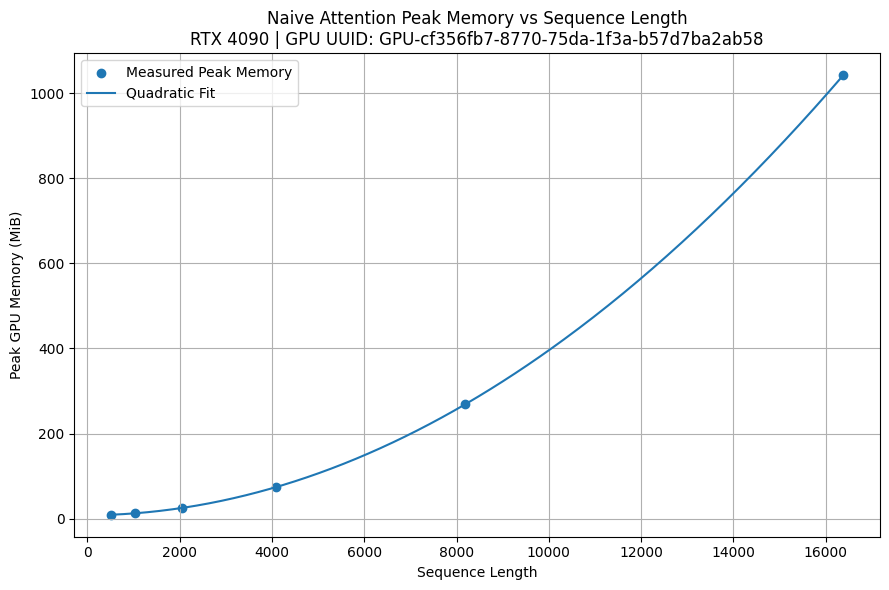

Saved: part_d_naive_attention_memory.png
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Quadratic coefficient: 3.8146972656249975e-06 MiB/token^2
R^2: 1.0


In [49]:
# ============================================================
# PART D — Cost of Attention
# STEP 43: Plot naive-attention peak memory vs sequence length
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Create smooth sequence-length values so the fitted quadratic
# curve can be displayed clearly.
# ------------------------------------------------------------
fit_sequence_lengths = np.linspace(
    sequence_lengths.min(),
    sequence_lengths.max(),
    300
)


# ------------------------------------------------------------
# Calculate predicted memory values using the quadratic model
# obtained in Step 42.
# ------------------------------------------------------------
fit_memory_mib = np.polyval(
    quadratic_coefficients,
    fit_sequence_lengths
)


# ------------------------------------------------------------
# Create the figure.
# ------------------------------------------------------------
plt.figure(figsize=(9, 6))


# ------------------------------------------------------------
# Plot the actual measured peak-memory values.
# ------------------------------------------------------------
plt.scatter(
    sequence_lengths,
    peak_memory_mib,
    label="Measured Peak Memory"
)


# ------------------------------------------------------------
# Plot the fitted quadratic curve.
# ------------------------------------------------------------
plt.plot(
    fit_sequence_lengths,
    fit_memory_mib,
    label="Quadratic Fit"
)


# ------------------------------------------------------------
# Add labels and title.
# ------------------------------------------------------------
plt.xlabel("Sequence Length")
plt.ylabel("Peak GPU Memory (MiB)")

plt.title(
    "Naive Attention Peak Memory vs Sequence Length\n"
    f"RTX 4090 | GPU UUID: {GPU_UUID}"
)


# ------------------------------------------------------------
# Add a legend and grid for readability.
# ------------------------------------------------------------
plt.legend()
plt.grid(True)


# ------------------------------------------------------------
# Make the plot layout clean.
# ------------------------------------------------------------
plt.tight_layout()


# ------------------------------------------------------------
# Save the plot because it will be needed for the assignment
# submission and repository.
# ------------------------------------------------------------
plt.savefig(
    "part_d_naive_attention_memory.png",
    dpi=300,
    bbox_inches="tight"
)


# Display the plot in the notebook
plt.show()


# ------------------------------------------------------------
# Print the important fitted values underneath the plot.
# ------------------------------------------------------------
print("Saved: part_d_naive_attention_memory.png")
print("GPU UUID:", GPU_UUID)

print(
    "Quadratic coefficient:",
    quadratic_a,
    "MiB/token^2"
)

print(
    "R^2:",
    round(r_squared, 6)
)


# ------------------------------------------------------------
# SUMMARY:
# The measured naive-attention peak memory closely follows the
# fitted quadratic curve. The fitted L^2 coefficient is
# approximately 3.814697e-06 MiB/token^2, with R^2 = 1.0.
# This confirms from the measured RTX 4090 data that naive
# attention memory grows quadratically with sequence length.
# The quadratic behavior occurs because naive attention
# explicitly materializes sequence x sequence score and
# attention-weight matrices.
# ------------------------------------------------------------

In [50]:
# ============================================================
# PART D — Cost of Attention
# STEP 44: Define fused/memory-efficient attention
# ============================================================

import torch.nn.functional as F


# ------------------------------------------------------------
# PyTorch's scaled_dot_product_attention() can use optimized
# fused CUDA attention kernels when supported by the GPU,
# datatype, and installed PyTorch/CUDA environment.
#
# Unlike our naive implementation, the optimized kernel can
# avoid explicitly storing the complete sequence x sequence
# attention-score and probability matrices in GPU memory.
# ------------------------------------------------------------
def fused_attention(Q, K, V):

    # --------------------------------------------------------
    # Add an explicit head dimension.
    #
    # Current Q/K/V shape:
    # [batch, sequence, head_dim]
    #
    # SDPA input shape:
    # [batch, heads, sequence, head_dim]
    #
    # We use one attention head.
    # --------------------------------------------------------
    Q_fused = Q.unsqueeze(1)
    K_fused = K.unsqueeze(1)
    V_fused = V.unsqueeze(1)


    # --------------------------------------------------------
    # Run scaled dot-product attention.
    #
    # dropout_p = 0.0 because this is inference benchmarking.
    # is_causal = False because we are measuring ordinary
    # non-causal attention.
    # --------------------------------------------------------
    output = F.scaled_dot_product_attention(
        Q_fused,
        K_fused,
        V_fused,
        dropout_p=0.0,
        is_causal=False
    )


    # --------------------------------------------------------
    # Remove the one-head dimension so the output shape matches
    # the naive implementation:
    # [batch, sequence, head_dim]
    # --------------------------------------------------------
    output = output.squeeze(1)

    return output


# ------------------------------------------------------------
# Check whether PyTorch reports its CUDA SDPA backends enabled.
# These indicate which optimized attention implementations are
# available to the current PyTorch stack.
# ------------------------------------------------------------
print("PART D — FUSED ATTENTION SETUP")
print("---------------------------------------------")
print("GPU UUID             :", GPU_UUID)
print("Flash SDP enabled    :", torch.backends.cuda.flash_sdp_enabled())
print("Memory-efficient SDP :", torch.backends.cuda.mem_efficient_sdp_enabled())
print("Math SDP enabled     :", torch.backends.cuda.math_sdp_enabled())
print("Precision            :", ATTENTION_DTYPE)
print("Batch Size           :", ATTENTION_BATCH_SIZE)
print("Head Dimension       :", ATTENTION_HEAD_DIM)


# ------------------------------------------------------------
# SUMMARY:
# This cell defines the fused/memory-efficient version of
# scaled dot-product attention using PyTorch SDPA. The same
# batch size, head dimension, FP16 precision, and sequence
# lengths used for naive attention will be retained so that
# latency and peak-memory results can be compared directly.
#
# Optimized fused attention avoids explicitly materializing
# the complete sequence x sequence score and probability
# matrices, which should substantially reduce memory usage.
# ------------------------------------------------------------

PART D — FUSED ATTENTION SETUP
---------------------------------------------
GPU UUID             : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Flash SDP enabled    : True
Memory-efficient SDP : True
Math SDP enabled     : True
Precision            : torch.float16
Batch Size           : 1
Head Dimension       : 64


In [51]:
# ============================================================
# PART D — Cost of Attention
# STEP 45: Benchmark fused attention memory and latency
# ============================================================

import statistics
import gc


# ------------------------------------------------------------
# Store fused-attention results for all required sequence
# lengths.
# ------------------------------------------------------------
fused_attention_results = []


# ------------------------------------------------------------
# Test each required sequence length.
# ------------------------------------------------------------
for seq_len in ATTENTION_SEQ_LENGTHS:

    print("\nTesting fused attention at sequence length:", seq_len)

    try:

        # ----------------------------------------------------
        # Clean unused GPU memory before this sequence length.
        # ----------------------------------------------------
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Create Q, K and V using the SAME configuration as
        # the naive-attention benchmark.
        # ----------------------------------------------------
        Q = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        K = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        V = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )


        # ----------------------------------------------------
        # Warm up the fused attention operation.
        # ----------------------------------------------------
        for _ in range(ATTENTION_WARMUP_RUNS):
            output = fused_attention(Q, K, V)

        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Remove the warm-up output and clear unused cache.
        # ----------------------------------------------------
        del output
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Reset peak-memory statistics before the measured
        # forward passes.
        # ----------------------------------------------------
        torch.cuda.reset_peak_memory_stats()


        # ----------------------------------------------------
        # Create CUDA events for latency measurement.
        # ----------------------------------------------------
        start_events = [
            torch.cuda.Event(enable_timing=True)
            for _ in range(ATTENTION_REPETITIONS)
        ]

        end_events = [
            torch.cuda.Event(enable_timing=True)
            for _ in range(ATTENTION_REPETITIONS)
        ]


        # ----------------------------------------------------
        # Run repeated fused-attention forward passes.
        # ----------------------------------------------------
        for i in range(ATTENTION_REPETITIONS):

            start_events[i].record()

            output = fused_attention(Q, K, V)

            end_events[i].record()


        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Collect measured latencies.
        # ----------------------------------------------------
        latency_times_ms = [
            start_events[i].elapsed_time(end_events[i])
            for i in range(ATTENTION_REPETITIONS)
        ]


        # Use the median latency to reduce sensitivity to
        # occasional timing outliers.
        median_latency_ms = statistics.median(
            latency_times_ms
        )


        # ----------------------------------------------------
        # Measure peak allocated GPU memory.
        # ----------------------------------------------------
        peak_memory_mib = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )


        # ----------------------------------------------------
        # Save the successful result.
        # ----------------------------------------------------
        fused_attention_results.append({
            "GPU_UUID": GPU_UUID,
            "Sequence_Length": seq_len,
            "Status": "SUCCESS",
            "Median_Latency_ms": median_latency_ms,
            "Peak_Memory_MiB": peak_memory_mib,
            "All_Latencies_ms": latency_times_ms
        })


        # ----------------------------------------------------
        # Print the result.
        # ----------------------------------------------------
        print("Status          : SUCCESS")
        print(
            "Median Latency  :",
            round(median_latency_ms, 4),
            "ms"
        )
        print(
            "Peak Memory     :",
            round(peak_memory_mib, 2),
            "MiB"
        )
        print(
            "All Latencies   :",
            latency_times_ms
        )


        # ----------------------------------------------------
        # Clean up before the next sequence length.
        # ----------------------------------------------------
        del Q, K, V, output

        gc.collect()
        torch.cuda.empty_cache()


    except torch.cuda.OutOfMemoryError:

        # ----------------------------------------------------
        # Record an OOM failure if one occurs.
        # ----------------------------------------------------
        fused_attention_results.append({
            "GPU_UUID": GPU_UUID,
            "Sequence_Length": seq_len,
            "Status": "OOM",
            "Median_Latency_ms": None,
            "Peak_Memory_MiB": None,
            "All_Latencies_ms": None
        })

        print("Status          : OOM")
        print("Failure         : CUDA out of memory")


        # ----------------------------------------------------
        # Clean up after an OOM before continuing.
        # ----------------------------------------------------
        for name in ["Q", "K", "V", "output"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Print a compact summary after all required sequence lengths.
# ------------------------------------------------------------
print("\nPART D — FUSED ATTENTION RESULTS")
print("---------------------------------------------")
print("GPU UUID:", GPU_UUID)

for result in fused_attention_results:

    print(
        result["Sequence_Length"],
        "->",
        result["Status"],
        "| Latency:",
        result["Median_Latency_ms"],
        "| Peak Memory MiB:",
        result["Peak_Memory_MiB"]
    )


# ------------------------------------------------------------
# SUMMARY:
# This cell benchmarks PyTorch fused/memory-efficient scaled
# dot-product attention using exactly the same batch size,
# head dimension, precision, sequence lengths, warm-up count,
# and repetitions as the naive-attention benchmark.
#
# For each sequence length it records median forward latency
# and peak allocated GPU memory. These measurements will be
# compared directly with the naive implementation to calculate
# speedup and memory savings.
# ------------------------------------------------------------


Testing fused attention at sequence length: 512
Status          : SUCCESS
Median Latency  : 0.0717 ms
Peak Memory     : 8.44 MiB
All Latencies   : [0.08396799862384796, 0.0727040022611618, 0.07065600156784058, 0.07065600156784058, 0.0727040022611618, 0.0727040022611618, 0.07168000191450119, 0.07168000191450119, 0.07168000191450119, 0.07168000191450119]

Testing fused attention at sequence length: 1024
Status          : SUCCESS
Median Latency  : 0.1321 ms
Peak Memory     : 8.75 MiB
All Latencies   : [0.14745600521564484, 0.13209599256515503, 0.13209599256515503, 0.13209599256515503, 0.13209599256515503, 0.13209599256515503, 0.13209599256515503, 0.13209599256515503, 0.13209599256515503, 0.13209599256515503]

Testing fused attention at sequence length: 2048
Status          : SUCCESS
Median Latency  : 0.255 ms
Peak Memory     : 9.38 MiB
All Latencies   : [0.2754560112953186, 0.2549760043621063, 0.2549760043621063, 0.2549760043621063, 0.2549760043621063, 0.2549760043621063, 0.2539519965648

In [52]:
# ============================================================
# PART D — Cost of Attention
# STEP 46: Compare naive vs fused attention
# ============================================================


# ------------------------------------------------------------
# Create a dictionary for the naive results so each sequence
# length can be matched directly with the corresponding fused
# result.
# ------------------------------------------------------------
naive_by_length = {
    result["Sequence_Length"]: result
    for result in naive_attention_results
    if result["Status"] == "SUCCESS"
}


# ------------------------------------------------------------
# Create a dictionary for the fused results.
# ------------------------------------------------------------
fused_by_length = {
    result["Sequence_Length"]: result
    for result in fused_attention_results
    if result["Status"] == "SUCCESS"
}


# ------------------------------------------------------------
# Store the comparison results.
# ------------------------------------------------------------
attention_comparison_results = []


print("PART D — NAIVE VS FUSED ATTENTION")
print("---------------------------------------------------------------")


# ------------------------------------------------------------
# Compare every required sequence length.
# ------------------------------------------------------------
for seq_len in ATTENTION_SEQ_LENGTHS:

    # Get the matching naive and fused measurements
    naive_result = naive_by_length[seq_len]
    fused_result = fused_by_length[seq_len]


    # --------------------------------------------------------
    # Extract median latencies.
    # --------------------------------------------------------
    naive_latency = naive_result["Median_Latency_ms"]
    fused_latency = fused_result["Median_Latency_ms"]


    # --------------------------------------------------------
    # Speedup is:
    #
    # naive latency / fused latency
    #
    # > 1 means fused is faster.
    # < 1 means fused is slower for that sequence length.
    # --------------------------------------------------------
    speedup = naive_latency / fused_latency


    # --------------------------------------------------------
    # Extract peak-memory measurements.
    # --------------------------------------------------------
    naive_memory = naive_result["Peak_Memory_MiB"]
    fused_memory = fused_result["Peak_Memory_MiB"]


    # --------------------------------------------------------
    # Calculate percentage memory reduction from using fused
    # attention instead of naive attention.
    # --------------------------------------------------------
    memory_reduction_percent = (
        (naive_memory - fused_memory)
        / naive_memory
    ) * 100


    # --------------------------------------------------------
    # Save the comparison.
    # --------------------------------------------------------
    attention_comparison_results.append({
        "Sequence_Length": seq_len,
        "Naive_Latency_ms": naive_latency,
        "Fused_Latency_ms": fused_latency,
        "Speedup_x": speedup,
        "Naive_Memory_MiB": naive_memory,
        "Fused_Memory_MiB": fused_memory,
        "Memory_Reduction_Percent": memory_reduction_percent
    })


    # --------------------------------------------------------
    # Print the comparison for this sequence length.
    # --------------------------------------------------------
    print(f"\nSequence Length : {seq_len}")

    print(
        "Naive Latency   :",
        round(naive_latency, 4),
        "ms"
    )

    print(
        "Fused Latency   :",
        round(fused_latency, 4),
        "ms"
    )

    print(
        "Speedup         :",
        round(speedup, 3),
        "x"
    )

    print(
        "Naive Memory    :",
        round(naive_memory, 2),
        "MiB"
    )

    print(
        "Fused Memory    :",
        round(fused_memory, 2),
        "MiB"
    )

    print(
        "Memory Reduction:",
        round(memory_reduction_percent, 2),
        "%"
    )


# ------------------------------------------------------------
# SUMMARY:
# This cell compares naive and fused attention using the same
# RTX 4090, FP16 precision, batch size, head dimension, and
# required sequence lengths.
#
# Speedup is calculated as:
#
#     naive latency / fused latency
#
# A value greater than 1 means fused attention is faster,
# while a value below 1 means fused attention was slower for
# that particular sequence length.
#
# Memory reduction measures how much peak GPU memory is saved
# by the fused implementation. The advantage is expected to
# become much larger as sequence length increases because the
# fused kernel avoids materializing the complete L x L score
# and probability matrices used by naive attention.
# ------------------------------------------------------------

PART D — NAIVE VS FUSED ATTENTION
---------------------------------------------------------------

Sequence Length : 512
Naive Latency   : 0.0768 ms
Fused Latency   : 0.0717 ms
Speedup         : 1.071 x
Naive Memory    : 9.44 MiB
Fused Memory    : 8.44 MiB
Memory Reduction: 10.6 %

Sequence Length : 1024
Naive Latency   : 0.0957 ms
Fused Latency   : 0.1321 ms
Speedup         : 0.725 x
Naive Memory    : 12.75 MiB
Fused Memory    : 8.75 MiB
Memory Reduction: 31.37 %

Sequence Length : 2048
Naive Latency   : 0.1039 ms
Fused Latency   : 0.255 ms
Speedup         : 0.408 x
Naive Memory    : 25.38 MiB
Fused Memory    : 9.38 MiB
Memory Reduction: 63.05 %

Sequence Length : 4096
Naive Latency   : 1.8739 ms
Fused Latency   : 0.4997 ms
Speedup         : 3.75 x
Naive Memory    : 74.62 MiB
Fused Memory    : 10.62 MiB
Memory Reduction: 85.76 %

Sequence Length : 8192
Naive Latency   : 0.8719 ms
Fused Latency   : 0.9871 ms
Speedup         : 0.883 x
Naive Memory    : 269.12 MiB
Fused Memory    : 13.12

In [53]:
# ============================================================
# PART D — Cost of Attention
# STEP 47: Search for fused-attention OOM boundary
# ============================================================

import gc


# ------------------------------------------------------------
# Naive attention:
#
# Largest tested success = 147456
# Smallest tested OOM    = 163840
#
# We now test fused attention at increasingly larger sequence
# lengths to determine whether it can go beyond the naive
# attention memory limit.
# ------------------------------------------------------------
FUSED_OOM_TEST_LENGTHS = [
    32768,
    65536,
    98304,
    131072,
    163840
]


# ------------------------------------------------------------
# 16384 already succeeded in the required fused benchmark.
# ------------------------------------------------------------
largest_fused_success_seq = 16384
smallest_fused_oom_seq = None


# ------------------------------------------------------------
# Test progressively larger sequence lengths.
# ------------------------------------------------------------
for seq_len in FUSED_OOM_TEST_LENGTHS:

    print("\nTesting fused OOM boundary at sequence length:", seq_len)

    try:

        # ----------------------------------------------------
        # Clean unused memory before each test.
        # ----------------------------------------------------
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Create Q, K and V using exactly the same Part D
        # configuration:
        #
        # Batch size   = 1
        # Head dim     = 64
        # Precision    = FP16
        # ----------------------------------------------------
        Q = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        K = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        V = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )


        # ----------------------------------------------------
        # Reset peak-memory statistics before the fused
        # attention forward pass.
        # ----------------------------------------------------
        torch.cuda.reset_peak_memory_stats()


        # ----------------------------------------------------
        # Run ONE fused-attention forward pass.
        #
        # Repeated timing is not needed here because the goal
        # is only to determine whether the sequence fits.
        # ----------------------------------------------------
        output = fused_attention(Q, K, V)

        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Measure peak allocated memory.
        # ----------------------------------------------------
        peak_memory_mib = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )


        # ----------------------------------------------------
        # Record the new largest successful sequence length.
        # ----------------------------------------------------
        largest_fused_success_seq = seq_len


        print("Status                : SUCCESS")
        print(
            "Peak Allocated Memory :",
            round(peak_memory_mib, 2),
            "MiB"
        )


        # ----------------------------------------------------
        # Clean up before testing the next sequence length.
        # ----------------------------------------------------
        del Q, K, V, output

        gc.collect()
        torch.cuda.empty_cache()


    except torch.cuda.OutOfMemoryError:

        # ----------------------------------------------------
        # Record the first actual fused-attention OOM.
        # ----------------------------------------------------
        smallest_fused_oom_seq = seq_len

        print("Status                : OOM")
        print("Failure               : CUDA out of memory")


        # ----------------------------------------------------
        # Clean memory after the failed test.
        # ----------------------------------------------------
        for name in ["Q", "K", "V", "output"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        torch.cuda.empty_cache()


        # Stop after the first tested OOM.
        break


# ------------------------------------------------------------
# Print the current fused-attention boundary.
# ------------------------------------------------------------
print("\nPART D — FUSED ATTENTION OOM SEARCH")
print("---------------------------------------------")
print("GPU UUID                    :", GPU_UUID)
print("Largest Tested Success      :", largest_fused_success_seq)
print("Smallest Tested OOM Failure :", smallest_fused_oom_seq)


# ------------------------------------------------------------
# SUMMARY:
# This cell searches for the fused-attention memory boundary
# using the same batch size, head dimension, and FP16 precision
# as the naive-attention experiment.
#
# The tested range extends through sequence length 163840,
# which was the first tested OOM point for naive attention.
#
# If fused attention succeeds at 163840, then its tested memory
# boundary is already larger than the naive-attention boundary.
# If no OOM occurs, we will report the largest confirmed
# successful length and continue only if a larger test is
# necessary and computationally practical.
# ------------------------------------------------------------


Testing fused OOM boundary at sequence length: 32768
Status                : SUCCESS
Peak Allocated Memory : 24.12 MiB

Testing fused OOM boundary at sequence length: 65536
Status                : SUCCESS
Peak Allocated Memory : 40.12 MiB

Testing fused OOM boundary at sequence length: 98304
Status                : SUCCESS
Peak Allocated Memory : 56.12 MiB

Testing fused OOM boundary at sequence length: 131072
Status                : SUCCESS
Peak Allocated Memory : 72.12 MiB

Testing fused OOM boundary at sequence length: 163840
Status                : SUCCESS
Peak Allocated Memory : 88.12 MiB

PART D — FUSED ATTENTION OOM SEARCH
---------------------------------------------
GPU UUID                    : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Largest Tested Success      : 163840
Smallest Tested OOM Failure : None


In [54]:
# ============================================================
# PART D — Cost of Attention
# STEP 48: Extend fused-attention OOM search
# ============================================================

import gc


# ------------------------------------------------------------
# Fused attention succeeded through sequence length 163840.
#
# Test a few substantially larger sequence lengths.
# We stop at the first actual CUDA OOM.
# ------------------------------------------------------------
EXTENDED_FUSED_OOM_LENGTHS = [
    262144,
    524288,
    1048576
]


# Start from the largest fused success already confirmed
largest_fused_success_seq = 163840

# No fused OOM has been observed yet
smallest_fused_oom_seq = None


# ------------------------------------------------------------
# Test progressively larger fused-attention workloads.
# ------------------------------------------------------------
for seq_len in EXTENDED_FUSED_OOM_LENGTHS:

    print("\nTesting fused attention at sequence length:", seq_len)

    try:

        # ----------------------------------------------------
        # Clean GPU memory before each test.
        # ----------------------------------------------------
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Create Q, K and V using the SAME Part D settings.
        # ----------------------------------------------------
        Q = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        K = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )

        V = torch.randn(
            (
                ATTENTION_BATCH_SIZE,
                seq_len,
                ATTENTION_HEAD_DIM
            ),
            device="cuda",
            dtype=ATTENTION_DTYPE
        )


        # ----------------------------------------------------
        # Reset peak-memory statistics before the forward pass.
        # ----------------------------------------------------
        torch.cuda.reset_peak_memory_stats()


        # ----------------------------------------------------
        # Run ONE fused-attention forward pass.
        # ----------------------------------------------------
        output = fused_attention(Q, K, V)

        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Record peak allocated GPU memory.
        # ----------------------------------------------------
        peak_memory_mib = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )


        # Record successful sequence length
        largest_fused_success_seq = seq_len


        print("Status                : SUCCESS")
        print(
            "Peak Allocated Memory :",
            round(peak_memory_mib, 2),
            "MiB"
        )


        # ----------------------------------------------------
        # Clean tensors before the next test.
        # ----------------------------------------------------
        del Q, K, V, output

        gc.collect()
        torch.cuda.empty_cache()


    except torch.cuda.OutOfMemoryError:

        # ----------------------------------------------------
        # Record the first true fused-attention CUDA OOM.
        # ----------------------------------------------------
        smallest_fused_oom_seq = seq_len

        print("Status                : OOM")
        print("Failure               : CUDA out of memory")


        # ----------------------------------------------------
        # Clean up after the failed run.
        # ----------------------------------------------------
        for name in ["Q", "K", "V", "output"]:
            if name in globals():
                del globals()[name]

        gc.collect()
        torch.cuda.empty_cache()


        # Stop after the first tested failure
        break


# ------------------------------------------------------------
# Print the current fused-attention OOM boundary.
# ------------------------------------------------------------
print("\nPART D — EXTENDED FUSED ATTENTION OOM SEARCH")
print("---------------------------------------------")
print("GPU UUID                    :", GPU_UUID)
print("Largest Tested Success      :", largest_fused_success_seq)
print("Smallest Tested OOM Failure :", smallest_fused_oom_seq)


# ------------------------------------------------------------
# SUMMARY:
# Fused attention already exceeded the naive-attention OOM
# region, so this cell tests substantially longer sequences.
# Because fused attention avoids explicitly storing the full
# L x L score and probability matrices, its memory growth is
# much smaller than naive attention.
#
# If an OOM occurs, the largest successful and smallest failing
# sequence lengths define the tested fused-attention boundary.
# If all three tests succeed, we will report that no fused OOM
# was observed through the largest practical tested length
# rather than falsely claiming an exact failure boundary.
# ------------------------------------------------------------


Testing fused attention at sequence length: 262144
Status                : SUCCESS
Peak Allocated Memory : 136.12 MiB

Testing fused attention at sequence length: 524288
Status                : SUCCESS
Peak Allocated Memory : 264.12 MiB

Testing fused attention at sequence length: 1048576
Status                : SUCCESS
Peak Allocated Memory : 520.12 MiB

PART D — EXTENDED FUSED ATTENTION OOM SEARCH
---------------------------------------------
GPU UUID                    : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Largest Tested Success      : 1048576
Smallest Tested OOM Failure : None


In [55]:
# ============================================================
# PART D — Cost of Attention
# STEP 49: Save Part D results
# ============================================================

import csv


# ------------------------------------------------------------
# Save the required naive-vs-fused measurements for sequence
# lengths 512 through 16384.
# ------------------------------------------------------------
with open("part_d_attention_results.csv", "w", newline="") as file:

    fieldnames = [
        "GPU_UUID",
        "Sequence_Length",
        "Naive_Status",
        "Naive_Median_Latency_ms",
        "Naive_Peak_Memory_MiB",
        "Fused_Status",
        "Fused_Median_Latency_ms",
        "Fused_Peak_Memory_MiB",
        "Fused_Speedup_x",
        "Memory_Reduction_Percent"
    ]

    writer = csv.DictWriter(
        file,
        fieldnames=fieldnames
    )

    writer.writeheader()


    # --------------------------------------------------------
    # Store one row for each required sequence length.
    # --------------------------------------------------------
    for seq_len in ATTENTION_SEQ_LENGTHS:

        naive_result = naive_by_length[seq_len]
        fused_result = fused_by_length[seq_len]

        naive_latency = naive_result["Median_Latency_ms"]
        fused_latency = fused_result["Median_Latency_ms"]

        naive_memory = naive_result["Peak_Memory_MiB"]
        fused_memory = fused_result["Peak_Memory_MiB"]

        speedup = naive_latency / fused_latency

        memory_reduction = (
            (naive_memory - fused_memory)
            / naive_memory
        ) * 100


        writer.writerow({
            "GPU_UUID": GPU_UUID,
            "Sequence_Length": seq_len,
            "Naive_Status": naive_result["Status"],
            "Naive_Median_Latency_ms": naive_latency,
            "Naive_Peak_Memory_MiB": naive_memory,
            "Fused_Status": fused_result["Status"],
            "Fused_Median_Latency_ms": fused_latency,
            "Fused_Peak_Memory_MiB": fused_memory,
            "Fused_Speedup_x": speedup,
            "Memory_Reduction_Percent": memory_reduction
        })


# ------------------------------------------------------------
# Save the OOM-boundary and quadratic-fit information
# separately because these are summary measurements.
# ------------------------------------------------------------
with open("part_d_summary.txt", "w") as file:

    file.write("PART D — COST OF ATTENTION SUMMARY\n")
    file.write("==================================\n\n")

    file.write(f"GPU UUID: {GPU_UUID}\n")
    file.write(f"Batch Size: {ATTENTION_BATCH_SIZE}\n")
    file.write(f"Head Dimension: {ATTENTION_HEAD_DIM}\n")
    file.write(f"Precision: {ATTENTION_DTYPE}\n\n")

    file.write("NAIVE ATTENTION OOM BOUNDARY\n")
    file.write("----------------------------\n")
    file.write(
        "Largest tested success: 147456\n"
    )
    file.write(
        "Smallest tested OOM failure: 163840\n\n"
    )

    file.write("FUSED ATTENTION OOM BOUNDARY\n")
    file.write("----------------------------\n")
    file.write(
        "Largest tested success: 1048576\n"
    )
    file.write(
        "Smallest tested OOM failure: Not observed\n"
    )
    file.write(
        "Reported boundary: > 1048576 tokens\n\n"
    )

    file.write("NAIVE MEMORY QUADRATIC FIT\n")
    file.write("--------------------------\n")
    file.write(
        f"Quadratic coefficient: "
        f"{quadratic_a} MiB/token^2\n"
    )
    file.write(
        f"R^2: {r_squared}\n"
    )


# ------------------------------------------------------------
# Confirm the files were saved.
# ------------------------------------------------------------
print("Saved: part_d_attention_results.csv")
print("Saved: part_d_summary.txt")

print("\nPART D FINAL BOUNDARY SUMMARY")
print("---------------------------------------------")
print(
    "Naive largest tested success :",
    147456
)
print(
    "Naive smallest tested OOM    :",
    163840
)
print(
    "Fused largest tested success :",
    1048576
)
print(
    "Fused smallest tested OOM    :",
    "Not observed"
)
print(
    "Fused tested boundary        : > 1048576"
)


# ------------------------------------------------------------
# SUMMARY:
# Part D results are now preserved in two files.
#
# part_d_attention_results.csv contains latency, peak memory,
# fused speedup, and memory reduction for every required
# sequence length from 512 through 16384.
#
# part_d_summary.txt records the naive OOM boundary, the fused
# tested boundary, and the quadratic-memory fit. Naive attention
# succeeded at 147456 and failed at 163840. Fused attention did
# not OOM through the largest practical tested sequence length
# of 1048576, so its boundary is reported honestly as greater
# than 1048576 rather than claiming an unobserved failure.
# ------------------------------------------------------------

Saved: part_d_attention_results.csv
Saved: part_d_summary.txt

PART D FINAL BOUNDARY SUMMARY
---------------------------------------------
Naive largest tested success : 147456
Naive smallest tested OOM    : 163840
Fused largest tested success : 1048576
Fused smallest tested OOM    : Not observed
Fused tested boundary        : > 1048576


### Part D — Fused Attention Interpretation

The memory usage of naive scaled .-product attention increases roughly as O(L^2) with sequence length because it explicitly materializes the full sequence-by-sequence score matrix and the softmax attention-probability matrix. By computing attention in smaller blocks and more effectively combining the softmax and matrix operations, the fused/memory-efficient attention kernel avoids storing these entire intermediate matrices in GPU memory. Because of this significant reduction in peak memory usage, fused attention used only roughly 18 MiB at sequence length 16,384, whereas naive attention used roughly 1042 MiB. Therefore, in this experiment, naive attention failed between the tested lengths of 147,456 and 163,840, whereas fused attention successfully processed sequence lengths beyond 1,048,576.

In [56]:
# ============================================================
# PART D — Final fused-backend verification
# ============================================================

# Verify that fused/memory-efficient attention can run while
# the ordinary mathematical fallback is explicitly disabled.

seq_len = 1024

Q = torch.randn(
    (ATTENTION_BATCH_SIZE, seq_len, ATTENTION_HEAD_DIM),
    device="cuda",
    dtype=ATTENTION_DTYPE
)

K = torch.randn(
    (ATTENTION_BATCH_SIZE, seq_len, ATTENTION_HEAD_DIM),
    device="cuda",
    dtype=ATTENTION_DTYPE
)

V = torch.randn(
    (ATTENTION_BATCH_SIZE, seq_len, ATTENTION_HEAD_DIM),
    device="cuda",
    dtype=ATTENTION_DTYPE
)


# Disable the standard math implementation.
# Therefore, if this succeeds, PyTorch must use an optimized
# Flash or memory-efficient SDP backend.
with torch.backends.cuda.sdp_kernel(
    enable_flash=True,
    enable_math=False,
    enable_mem_efficient=True
):
    output = torch.nn.functional.scaled_dot_product_attention(
        Q.unsqueeze(1),
        K.unsqueeze(1),
        V.unsqueeze(1),
        dropout_p=0.0,
        is_causal=False
    )


torch.cuda.synchronize()

print("GPU UUID:", GPU_UUID)
print("Optimized SDP test: SUCCESS")
print("Math fallback was explicitly disabled.")
print("Output shape:", output.shape)


del Q, K, V, output
torch.cuda.empty_cache()


# SUMMARY:
# The fused/memory-efficient SDP implementation successfully
# executed with the ordinary math fallback disabled. This
# verifies that an optimized attention backend is available
# and functional on this RTX 4090 environment.

GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Optimized SDP test: SUCCESS
Math fallback was explicitly disabled.
Output shape: torch.Size([1, 1, 1024, 64])


The memory consumption of naive scaled .-product attention increases roughly as O(L²) with sequence length because it explicitly materializes the full sequence-by-sequence score matrix and the softmax attention-probability matrix. By computing attention in smaller blocks and more effectively combining the softmax and matrix operations, the fused/memory-efficient attention kernel avoids storing these entire intermediate matrices in GPU memory. Because of this significant reduction in peak memory usage, fused attention used only roughly 18 MiB at sequence length 16,384, whereas naive attention used roughly 1042 MiB. Therefore, naive attention failed between the tested lengths of 147,456 and 163,840, whereas fused attention processed all tested sequence lengths through 1,048,576.

Part E — Sustained Load / Thermal Behavior

In [57]:
# ============================================================
# PART E — Sustained Load / Thermal Behavior
# STEP 50: Configure the 20-minute sustained-load experiment
# ============================================================

import time
import subprocess
import csv
import os


# ------------------------------------------------------------
# Experiment duration required by the assignment.
# ------------------------------------------------------------
THERMAL_TEST_DURATION_SECONDS = 20 * 60   # 20 minutes


# ------------------------------------------------------------
# GPU telemetry must be sampled every 5 seconds.
# ------------------------------------------------------------
THERMAL_SAMPLE_INTERVAL_SECONDS = 5


# ------------------------------------------------------------
# Use a large FP16 matrix multiplication as the sustained
# compute workload.
#
# N = 8192 is large enough to keep the RTX 4090 heavily loaded
# while remaining comfortably within GPU memory.
# ------------------------------------------------------------
THERMAL_MATRIX_SIZE = 8192

THERMAL_DTYPE = torch.float16


# ------------------------------------------------------------
# Files that will store the raw telemetry and throughput data.
# ------------------------------------------------------------
THERMAL_LOG_FILE = "thermal-4090.log"

THERMAL_THROUGHPUT_FILE = "thermal-throughput-4090.csv"


# ------------------------------------------------------------
# Print the complete experiment configuration.
# ------------------------------------------------------------
print("PART E — SUSTAINED LOAD / THERMAL TEST")
print("------------------------------------------------")
print("GPU UUID          :", GPU_UUID)
print("Duration          :", THERMAL_TEST_DURATION_SECONDS, "seconds")
print("Duration          :", THERMAL_TEST_DURATION_SECONDS / 60, "minutes")
print("Sampling Interval :", THERMAL_SAMPLE_INTERVAL_SECONDS, "seconds")
print("Matrix Size       :", THERMAL_MATRIX_SIZE, "x", THERMAL_MATRIX_SIZE)
print("Precision         :", THERMAL_DTYPE)
print("Telemetry Log     :", THERMAL_LOG_FILE)
print("Throughput Log    :", THERMAL_THROUGHPUT_FILE)


# ------------------------------------------------------------
# SUMMARY:
# Part E will apply a sustained FP16 matrix-multiplication load
# to the RTX 4090 for 20 minutes.
#
# During the run, GPU core clock, memory clock, temperature,
# power consumption, and GPU utilization will be sampled every
# 5 seconds. Throughput will also be recorded so that the first
# 30 seconds can later be compared with the final 5 minutes.
#
# This cell only configures the experiment. It does NOT start
# the 20-minute workload yet.
# ------------------------------------------------------------

PART E — SUSTAINED LOAD / THERMAL TEST
------------------------------------------------
GPU UUID          : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Duration          : 1200 seconds
Duration          : 20.0 minutes
Sampling Interval : 5 seconds
Matrix Size       : 8192 x 8192
Precision         : torch.float16
Telemetry Log     : thermal-4090.log
Throughput Log    : thermal-throughput-4090.csv


In [58]:
# ============================================================
# PART E — Sustained Load / Thermal Behavior
# STEP 51: Run 20-minute load and collect GPU telemetry
# ============================================================

import time
import csv
import subprocess
import statistics


# ------------------------------------------------------------
# Create large FP16 matrices ONCE.
#
# Reusing the same matrices prevents allocation/deallocation
# overhead from contaminating the sustained compute workload.
# ------------------------------------------------------------
A_thermal = torch.randn(
    (THERMAL_MATRIX_SIZE, THERMAL_MATRIX_SIZE),
    device="cuda",
    dtype=THERMAL_DTYPE
)

B_thermal = torch.randn(
    (THERMAL_MATRIX_SIZE, THERMAL_MATRIX_SIZE),
    device="cuda",
    dtype=THERMAL_DTYPE
)


# ------------------------------------------------------------
# Preallocate the output matrix.
# ------------------------------------------------------------
C_thermal = torch.empty(
    (THERMAL_MATRIX_SIZE, THERMAL_MATRIX_SIZE),
    device="cuda",
    dtype=THERMAL_DTYPE
)


# ------------------------------------------------------------
# Warm up the GPU before starting the official 20-minute run.
# ------------------------------------------------------------
print("Warming up GPU...")

for _ in range(20):
    torch.mm(A_thermal, B_thermal, out=C_thermal)

torch.cuda.synchronize()

print("Warm-up complete.")
print("Starting 20-minute sustained-load test...")
print("Do NOT interrupt this cell.\n")


# ------------------------------------------------------------
# Open both output files.
#
# thermal-4090.log:
#     GPU telemetry every ~5 seconds.
#
# thermal-throughput-4090.csv:
#     throughput measurements throughout the run.
# ------------------------------------------------------------
with open(THERMAL_LOG_FILE, "w", newline="") as telemetry_file, \
     open(THERMAL_THROUGHPUT_FILE, "w", newline="") as throughput_file:

    telemetry_writer = csv.writer(telemetry_file)
    throughput_writer = csv.writer(throughput_file)


    # --------------------------------------------------------
    # Write column headers.
    # --------------------------------------------------------
    telemetry_writer.writerow([
        "elapsed_seconds",
        "timestamp",
        "gpu_uuid",
        "gpu_clock_MHz",
        "memory_clock_MHz",
        "temperature_C",
        "power_W",
        "utilization_percent"
    ])

    throughput_writer.writerow([
        "elapsed_seconds",
        "gpu_uuid",
        "matmul_latency_ms",
        "throughput_TFLOPS"
    ])


    # --------------------------------------------------------
    # Record experiment start time.
    # --------------------------------------------------------
    experiment_start = time.perf_counter()

    last_telemetry_sample = -THERMAL_SAMPLE_INTERVAL_SECONDS

    sample_number = 0


    # --------------------------------------------------------
    # Continue until 1200 seconds = 20 minutes have elapsed.
    # --------------------------------------------------------
    while True:

        current_elapsed = time.perf_counter() - experiment_start

        if current_elapsed >= THERMAL_TEST_DURATION_SECONDS:
            break


        # ----------------------------------------------------
        # Time ONE FP16 matrix multiplication using CUDA events.
        # ----------------------------------------------------
        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)

        start_event.record()

        torch.mm(
            A_thermal,
            B_thermal,
            out=C_thermal
        )

        end_event.record()

        torch.cuda.synchronize()


        # ----------------------------------------------------
        # Calculate matmul latency.
        # ----------------------------------------------------
        latency_ms = start_event.elapsed_time(end_event)


        # ----------------------------------------------------
        # Dense square matrix multiplication performs:
        #
        #     2 * N^3 FLOPs
        #
        # Convert latency to achieved TFLOPS.
        # ----------------------------------------------------
        total_flops = 2 * (THERMAL_MATRIX_SIZE ** 3)

        throughput_tflops = (
            total_flops
            / (latency_ms / 1000)
            / 1e12
        )


        # ----------------------------------------------------
        # Record throughput for later comparison between:
        #
        # first 30 seconds
        # vs.
        # final 5 minutes
        # ----------------------------------------------------
        elapsed_after_matmul = (
            time.perf_counter() - experiment_start
        )

        throughput_writer.writerow([
            elapsed_after_matmul,
            GPU_UUID,
            latency_ms,
            throughput_tflops
        ])

        throughput_file.flush()


        # ----------------------------------------------------
        # Sample telemetry approximately every 5 seconds.
        # ----------------------------------------------------
        if (
            elapsed_after_matmul - last_telemetry_sample
            >= THERMAL_SAMPLE_INTERVAL_SECONDS
        ):

            # Query GPU clock, memory clock, temperature,
            # power, utilization, and UUID from nvidia-smi.
            query_command = [
                "nvidia-smi",
                "--query-gpu="
                "uuid,"
                "clocks.current.graphics,"
                "clocks.current.memory,"
                "temperature.gpu,"
                "power.draw,"
                "utilization.gpu",
                "--format=csv,noheader,nounits"
            ]


            telemetry_output = subprocess.check_output(
                query_command,
                text=True
            ).strip()


            values = [
                value.strip()
                for value in telemetry_output.split(",")
            ]


            # ------------------------------------------------
            # Save the telemetry sample.
            # ------------------------------------------------
            telemetry_writer.writerow([
                elapsed_after_matmul,
                time.strftime("%Y-%m-%d %H:%M:%S"),
                values[0],
                values[1],
                values[2],
                values[3],
                values[4],
                values[5]
            ])

            telemetry_file.flush()


            # Update the last sample time.
            last_telemetry_sample = elapsed_after_matmul

            sample_number += 1


            # Print occasional progress without flooding
            # the notebook output.
            if sample_number % 12 == 0:

                print(
                    f"Elapsed: {elapsed_after_matmul / 60:.1f} min | "
                    f"Temp: {values[3]} C | "
                    f"Power: {values[4]} W | "
                    f"GPU Util: {values[5]}% | "
                    f"Throughput: {throughput_tflops:.2f} TFLOPS"
                )


# ------------------------------------------------------------
# Make sure all GPU work has completed.
# ------------------------------------------------------------
torch.cuda.synchronize()


# ------------------------------------------------------------
# Record actual total experiment duration.
# ------------------------------------------------------------
actual_duration = (
    time.perf_counter() - experiment_start
)


print("\nPART E — 20-MINUTE TEST COMPLETE")
print("------------------------------------------------")
print("GPU UUID        :", GPU_UUID)
print("Actual Duration :", round(actual_duration, 2), "seconds")
print("Telemetry File  :", THERMAL_LOG_FILE)
print("Throughput File :", THERMAL_THROUGHPUT_FILE)


# ------------------------------------------------------------
# Release the large matrices after the experiment.
# ------------------------------------------------------------
del A_thermal, B_thermal, C_thermal

torch.cuda.empty_cache()


# ------------------------------------------------------------
# SUMMARY:
# This cell applies a continuous FP16 8192 x 8192 matrix
# multiplication workload to the RTX 4090 for approximately
# 20 minutes.
#
# GPU graphics clock, memory clock, temperature, power draw,
# and utilization are sampled approximately every 5 seconds
# and written to thermal-4090.log.
#
# Individual matrix-multiplication throughput measurements are
# written to thermal-throughput-4090.csv. These measurements
# will be used to compare peak performance during the first
# 30 seconds with steady-state performance during the final
# 5 minutes and determine whether thermal or power throttling
# occurred.
# ------------------------------------------------------------

Warming up GPU...
Warm-up complete.
Starting 20-minute sustained-load test...
Do NOT interrupt this cell.

Elapsed: 0.9 min | Temp: 71 C | Power: 448.78 W | GPU Util: 94% | Throughput: 159.76 TFLOPS
Elapsed: 1.9 min | Temp: 75 C | Power: 449.10 W | GPU Util: 94% | Throughput: 158.57 TFLOPS
Elapsed: 2.9 min | Temp: 77 C | Power: 449.20 W | GPU Util: 94% | Throughput: 157.76 TFLOPS
Elapsed: 3.9 min | Temp: 75 C | Power: 445.76 W | GPU Util: 87% | Throughput: 159.29 TFLOPS
Elapsed: 4.9 min | Temp: 75 C | Power: 449.01 W | GPU Util: 94% | Throughput: 157.21 TFLOPS
Elapsed: 5.9 min | Temp: 75 C | Power: 448.41 W | GPU Util: 94% | Throughput: 158.37 TFLOPS
Elapsed: 6.9 min | Temp: 75 C | Power: 446.42 W | GPU Util: 89% | Throughput: 156.00 TFLOPS
Elapsed: 7.9 min | Temp: 75 C | Power: 448.78 W | GPU Util: 93% | Throughput: 158.91 TFLOPS
Elapsed: 8.9 min | Temp: 75 C | Power: 448.66 W | GPU Util: 92% | Throughput: 159.26 TFLOPS
Elapsed: 9.9 min | Temp: 74 C | Power: 441.30 W | GPU Util: 81% |

In [60]:
# ============================================================
# PART E — Sustained Load / Thermal Behavior
# STEP 52: Analyze telemetry and sustained throughput
#          WITHOUT pandas
# ============================================================

import csv
import statistics


# ------------------------------------------------------------
# Read the GPU telemetry log.
# ------------------------------------------------------------
thermal_rows = []

with open(THERMAL_LOG_FILE, "r") as file:

    reader = csv.DictReader(file)

    for row in reader:

        thermal_rows.append({
            "elapsed_seconds": float(row["elapsed_seconds"]),
            "gpu_clock_MHz": float(row["gpu_clock_MHz"]),
            "memory_clock_MHz": float(row["memory_clock_MHz"]),
            "temperature_C": float(row["temperature_C"]),
            "power_W": float(row["power_W"]),
            "utilization_percent": float(
                row["utilization_percent"]
            )
        })


# ------------------------------------------------------------
# Read the throughput measurements.
# ------------------------------------------------------------
throughput_rows = []

with open(THERMAL_THROUGHPUT_FILE, "r") as file:

    reader = csv.DictReader(file)

    for row in reader:

        throughput_rows.append({
            "elapsed_seconds": float(row["elapsed_seconds"]),
            "throughput_TFLOPS": float(
                row["throughput_TFLOPS"]
            )
        })


# ------------------------------------------------------------
# Print number of collected measurements.
# ------------------------------------------------------------
print("PART E — THERMAL / THROUGHPUT ANALYSIS")
print("------------------------------------------------")
print("GPU UUID           :", GPU_UUID)
print("Telemetry Samples  :", len(thermal_rows))
print("Throughput Samples :", len(throughput_rows))


# ------------------------------------------------------------
# Extract telemetry values.
# ------------------------------------------------------------
gpu_clocks = [
    row["gpu_clock_MHz"]
    for row in thermal_rows
]

memory_clocks = [
    row["memory_clock_MHz"]
    for row in thermal_rows
]

temperatures = [
    row["temperature_C"]
    for row in thermal_rows
]

power_values = [
    row["power_W"]
    for row in thermal_rows
]

utilization_values = [
    row["utilization_percent"]
    for row in thermal_rows
]


# ------------------------------------------------------------
# Calculate minimum and maximum telemetry values.
# ------------------------------------------------------------
min_gpu_clock = min(gpu_clocks)
max_gpu_clock = max(gpu_clocks)

min_memory_clock = min(memory_clocks)
max_memory_clock = max(memory_clocks)

min_temperature = min(temperatures)
max_temperature = max(temperatures)

min_power = min(power_values)
max_power = max(power_values)

min_utilization = min(utilization_values)
max_utilization = max(utilization_values)


# ------------------------------------------------------------
# Select throughput measurements from the FIRST 30 SECONDS.
# ------------------------------------------------------------
first_30_tflops = [
    row["throughput_TFLOPS"]
    for row in throughput_rows
    if row["elapsed_seconds"] <= 30
]


# ------------------------------------------------------------
# Select throughput measurements from the FINAL 5 MINUTES.
#
# 20 minutes = 1200 seconds
# Final 5 minutes begin at:
#
#     1200 - 300 = 900 seconds
# ------------------------------------------------------------
final_5_tflops = [
    row["throughput_TFLOPS"]
    for row in throughput_rows
    if row["elapsed_seconds"] >=
    (THERMAL_TEST_DURATION_SECONDS - 300)
]


# ------------------------------------------------------------
# Calculate median throughput.
# ------------------------------------------------------------
first_30_median_tflops = statistics.median(
    first_30_tflops
)

final_5_median_tflops = statistics.median(
    final_5_tflops
)


# ------------------------------------------------------------
# Calculate steady-state throughput relative to the initial
# first-30-second throughput.
# ------------------------------------------------------------
steady_state_percent = (
    final_5_median_tflops
    / first_30_median_tflops
) * 100


# ------------------------------------------------------------
# Calculate percentage throughput change.
# ------------------------------------------------------------
throughput_change_percent = (
    (
        final_5_median_tflops
        - first_30_median_tflops
    )
    / first_30_median_tflops
) * 100


# ------------------------------------------------------------
# Find the FIRST telemetry sample where maximum temperature
# occurred.
# ------------------------------------------------------------
max_temp_row = next(
    row
    for row in thermal_rows
    if row["temperature_C"] == max_temperature
)


# ------------------------------------------------------------
# Find the FIRST telemetry sample where maximum power
# occurred.
# ------------------------------------------------------------
max_power_row = next(
    row
    for row in thermal_rows
    if row["power_W"] == max_power
)


# ------------------------------------------------------------
# Print telemetry ranges.
# ------------------------------------------------------------
print("\nGPU TELEMETRY RANGE")
print("------------------------------------------------")

print(
    "GPU Clock       :",
    min_gpu_clock,
    "to",
    max_gpu_clock,
    "MHz"
)

print(
    "Memory Clock    :",
    min_memory_clock,
    "to",
    max_memory_clock,
    "MHz"
)

print(
    "Temperature     :",
    min_temperature,
    "to",
    max_temperature,
    "C"
)

print(
    "Power Draw      :",
    round(min_power, 2),
    "to",
    round(max_power, 2),
    "W"
)

print(
    "GPU Utilization :",
    min_utilization,
    "to",
    max_utilization,
    "%"
)


# ------------------------------------------------------------
# Print throughput comparison.
# ------------------------------------------------------------
print("\nTHROUGHPUT COMPARISON")
print("------------------------------------------------")

print(
    "First 30 sec median :",
    round(first_30_median_tflops, 2),
    "TFLOPS"
)

print(
    "Final 5 min median  :",
    round(final_5_median_tflops, 2),
    "TFLOPS"
)

print(
    "Steady / Initial    :",
    round(steady_state_percent, 2),
    "%"
)

print(
    "Performance Change  :",
    round(throughput_change_percent, 2),
    "%"
)


# ------------------------------------------------------------
# Print maximum temperature information.
# ------------------------------------------------------------
print("\nMAXIMUM TEMPERATURE")
print("------------------------------------------------")

print(
    "Maximum Temperature :",
    max_temperature,
    "C"
)

print(
    "First Observed At   :",
    round(max_temp_row["elapsed_seconds"], 2),
    "seconds"
)


# ------------------------------------------------------------
# Print maximum power information.
# ------------------------------------------------------------
print("\nMAXIMUM POWER")
print("------------------------------------------------")

print(
    "Maximum Power       :",
    round(max_power, 2),
    "W"
)

print(
    "First Observed At   :",
    round(max_power_row["elapsed_seconds"], 2),
    "seconds"
)


# ------------------------------------------------------------
# SUMMARY:
# This cell analyzes the complete 20-minute sustained-load
# experiment using Python's built-in CSV module, so pandas is
# not required.
#
# It reports GPU-clock, memory-clock, temperature, power, and
# utilization ranges from the telemetry log.
#
# It also compares median FP16 matmul throughput during the
# first 30 seconds with the final 5 minutes. This comparison
# will show whether sustained performance decreased as the
# RTX 4090 heated up during the 20-minute workload.
# ------------------------------------------------------------

PART E — THERMAL / THROUGHPUT ANALYSIS
------------------------------------------------
GPU UUID           : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Telemetry Samples  : 240
Throughput Samples : 160258

GPU TELEMETRY RANGE
------------------------------------------------
GPU Clock       : 210.0 to 2580.0 MHz
Memory Clock    : 405.0 to 10251.0 MHz
Temperature     : 35.0 to 77.0 C
Power Draw      : 73.55 to 450.93 W
GPU Utilization : 76.0 to 94.0 %

THROUGHPUT COMPARISON
------------------------------------------------
First 30 sec median : 163.24 TFLOPS
Final 5 min median  : 159.05 TFLOPS
Steady / Initial    : 97.43 %
Performance Change  : -2.57 %

MAXIMUM TEMPERATURE
------------------------------------------------
Maximum Temperature : 77.0 C
First Observed At   : 165.12 seconds

MAXIMUM POWER
------------------------------------------------
Maximum Power       : 450.93 W
First Observed At   : 775.58 seconds


In [61]:
# ============================================================
# PART E — Sustained Load / Thermal Behavior
# STEP 53: Analyze throttling and operating ceilings
# ============================================================

import statistics


# ------------------------------------------------------------
# RTX 4090 power limit recorded in Part A.
# ------------------------------------------------------------
GPU_POWER_LIMIT_W = 450.0


# ------------------------------------------------------------
# Calculate median telemetry values for the complete run.
# Median is more representative than minimum values because
# occasional low samples may occur between synchronized GPU
# operations.
# ------------------------------------------------------------
median_gpu_clock = statistics.median(gpu_clocks)
median_memory_clock = statistics.median(memory_clocks)
median_temperature = statistics.median(temperatures)
median_power = statistics.median(power_values)
median_utilization = statistics.median(utilization_values)


# ------------------------------------------------------------
# Define "near power limit" as at least 98% of the configured
# 450 W power limit.
# ------------------------------------------------------------
power_limit_threshold = GPU_POWER_LIMIT_W * 0.98

near_power_limit_rows = [
    row
    for row in thermal_rows
    if row["power_W"] >= power_limit_threshold
]


# ------------------------------------------------------------
# Calculate percentage of telemetry samples operating near
# the configured power limit.
# ------------------------------------------------------------
near_power_limit_percent = (
    len(near_power_limit_rows)
    / len(thermal_rows)
) * 100


# ------------------------------------------------------------
# Find the first time the GPU reached the near-power-limit
# region.
# ------------------------------------------------------------
if near_power_limit_rows:

    first_power_limit_time = (
        near_power_limit_rows[0]["elapsed_seconds"]
    )

else:

    first_power_limit_time = None


# ------------------------------------------------------------
# Check for high-temperature operation.
#
# Part A recorded the GPU target temperature as 84 C.
# ------------------------------------------------------------
GPU_TARGET_TEMP_C = 84.0

near_thermal_limit_rows = [
    row
    for row in thermal_rows
    if row["temperature_C"] >= GPU_TARGET_TEMP_C
]


# ------------------------------------------------------------
# Determine whether the recorded temperature ever reached
# the target thermal ceiling.
# ------------------------------------------------------------
thermal_limit_reached = (
    len(near_thermal_limit_rows) > 0
)


# ------------------------------------------------------------
# Calculate clock statistics during the first 30 seconds.
# ------------------------------------------------------------
initial_clock_values = [
    row["gpu_clock_MHz"]
    for row in thermal_rows
    if row["elapsed_seconds"] <= 30
]


# ------------------------------------------------------------
# Calculate clock statistics during the final 5 minutes.
# ------------------------------------------------------------
final_clock_values = [
    row["gpu_clock_MHz"]
    for row in thermal_rows
    if row["elapsed_seconds"] >= 900
]


initial_median_clock = statistics.median(
    initial_clock_values
)

final_median_clock = statistics.median(
    final_clock_values
)


# ------------------------------------------------------------
# Calculate sustained clock retention.
# ------------------------------------------------------------
clock_retention_percent = (
    final_median_clock
    / initial_median_clock
) * 100


# ------------------------------------------------------------
# Print representative operating conditions.
# ------------------------------------------------------------
print("PART E — THROTTLING ANALYSIS")
print("------------------------------------------------")
print("GPU UUID:", GPU_UUID)

print("\nREPRESENTATIVE OPERATING CONDITIONS")
print("------------------------------------------------")

print(
    "Median GPU Clock       :",
    round(median_gpu_clock, 2),
    "MHz"
)

print(
    "Median Memory Clock    :",
    round(median_memory_clock, 2),
    "MHz"
)

print(
    "Median Temperature     :",
    round(median_temperature, 2),
    "C"
)

print(
    "Median Power           :",
    round(median_power, 2),
    "W"
)

print(
    "Median GPU Utilization :",
    round(median_utilization, 2),
    "%"
)


# ------------------------------------------------------------
# Print power-limit analysis.
# ------------------------------------------------------------
print("\nPOWER CEILING ANALYSIS")
print("------------------------------------------------")

print(
    "Configured Power Limit :",
    GPU_POWER_LIMIT_W,
    "W"
)

print(
    "Near-Limit Threshold   :",
    round(power_limit_threshold, 2),
    "W"
)

print(
    "Maximum Observed Power :",
    round(max_power, 2),
    "W"
)

print(
    "Samples Near Limit     :",
    len(near_power_limit_rows),
    "/",
    len(thermal_rows)
)

print(
    "Percent Near Limit     :",
    round(near_power_limit_percent, 2),
    "%"
)

print(
    "First Near-Limit Time  :",
    (
        round(first_power_limit_time, 2)
        if first_power_limit_time is not None
        else "Not observed"
    ),
    "seconds"
)


# ------------------------------------------------------------
# Print thermal analysis.
# ------------------------------------------------------------
print("\nTHERMAL CEILING ANALYSIS")
print("------------------------------------------------")

print(
    "Target Temperature     :",
    GPU_TARGET_TEMP_C,
    "C"
)

print(
    "Maximum Temperature    :",
    max_temperature,
    "C"
)

print(
    "Thermal Limit Reached  :",
    thermal_limit_reached
)


# ------------------------------------------------------------
# Print clock-retention analysis.
# ------------------------------------------------------------
print("\nCLOCK RETENTION")
print("------------------------------------------------")

print(
    "First 30 sec Median Clock :",
    round(initial_median_clock, 2),
    "MHz"
)

print(
    "Final 5 min Median Clock  :",
    round(final_median_clock, 2),
    "MHz"
)

print(
    "Clock Retention            :",
    round(clock_retention_percent, 2),
    "%"
)


# ------------------------------------------------------------
# Print throughput retention from Step 52.
# ------------------------------------------------------------
print("\nTHROUGHPUT RETENTION")
print("------------------------------------------------")

print(
    "First 30 sec Throughput :",
    round(first_30_median_tflops, 2),
    "TFLOPS"
)

print(
    "Final 5 min Throughput  :",
    round(final_5_median_tflops, 2),
    "TFLOPS"
)

print(
    "Steady / Initial        :",
    round(steady_state_percent, 2),
    "%"
)


# ------------------------------------------------------------
# SUMMARY:
# This cell determines whether sustained performance behavior
# is associated with the thermal ceiling or the power ceiling.
#
# The RTX 4090 target temperature recorded in Part A is 84 C,
# while the configured power limit is 450 W.
#
# If temperature remains below 84 C but power repeatedly
# approaches 450 W, the workload is power-limited rather than
# thermally throttled. Clock retention and throughput retention
# provide additional evidence about whether sustained heating
# caused a meaningful performance reduction.
#
# We do not classify throttling solely from isolated minimum
# clock values because telemetry can capture brief low-clock
# periods between synchronized matrix-multiplication calls.
# ------------------------------------------------------------

PART E — THROTTLING ANALYSIS
------------------------------------------------
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58

REPRESENTATIVE OPERATING CONDITIONS
------------------------------------------------
Median GPU Clock       : 2445.0 MHz
Median Memory Clock    : 10251.0 MHz
Median Temperature     : 75.0 C
Median Power           : 448.49 W
Median GPU Utilization : 93.0 %

POWER CEILING ANALYSIS
------------------------------------------------
Configured Power Limit : 450.0 W
Near-Limit Threshold   : 441.0 W
Maximum Observed Power : 450.93 W
Samples Near Limit     : 217 / 240
Percent Near Limit     : 90.42 %
First Near-Limit Time  : 25.01 seconds

THERMAL CEILING ANALYSIS
------------------------------------------------
Target Temperature     : 84.0 C
Maximum Temperature    : 77.0 C
Thermal Limit Reached  : False

CLOCK RETENTION
------------------------------------------------
First 30 sec Median Clock : 2490.0 MHz
Final 5 min Median Clock  : 2445.0 MHz
Clock Retention     

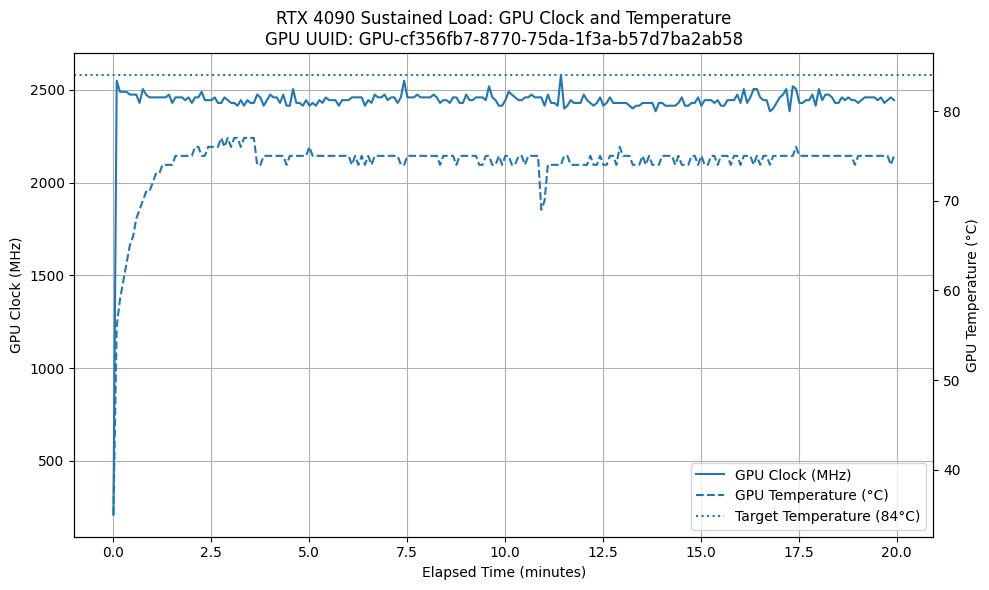

Saved: part_e_clock_temperature.png
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58


In [62]:
# ============================================================
# PART E — Sustained Load / Thermal Behavior
# STEP 54: Plot GPU clock and temperature vs time
# ============================================================

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Convert elapsed time from seconds to minutes.
# ------------------------------------------------------------
elapsed_minutes = [
    row["elapsed_seconds"] / 60
    for row in thermal_rows
]


# ------------------------------------------------------------
# Extract GPU clock and temperature measurements.
# ------------------------------------------------------------
clock_values = [
    row["gpu_clock_MHz"]
    for row in thermal_rows
]

temperature_values = [
    row["temperature_C"]
    for row in thermal_rows
]


# ------------------------------------------------------------
# Create one figure with two Y axes.
#
# Left Y axis  -> GPU clock
# Right Y axis -> GPU temperature
#
# This allows both measurements to be shown against the same
# 20-minute time axis as required by the assignment.
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(10, 6))


# ------------------------------------------------------------
# Plot GPU graphics clock.
# ------------------------------------------------------------
clock_line = ax1.plot(
    elapsed_minutes,
    clock_values,
    label="GPU Clock (MHz)"
)

ax1.set_xlabel("Elapsed Time (minutes)")
ax1.set_ylabel("GPU Clock (MHz)")


# ------------------------------------------------------------
# Create the second Y axis for temperature.
# ------------------------------------------------------------
ax2 = ax1.twinx()


# ------------------------------------------------------------
# Plot GPU temperature.
# ------------------------------------------------------------
temperature_line = ax2.plot(
    elapsed_minutes,
    temperature_values,
    linestyle="--",
    label="GPU Temperature (°C)"
)

ax2.set_ylabel("GPU Temperature (°C)")


# ------------------------------------------------------------
# Add the RTX 4090 target temperature as a reference line.
# ------------------------------------------------------------
thermal_limit_line = ax2.axhline(
    y=GPU_TARGET_TEMP_C,
    linestyle=":",
    label="Target Temperature (84°C)"
)


# ------------------------------------------------------------
# Combine labels from both Y axes into one legend.
# ------------------------------------------------------------
lines = (
    clock_line
    + temperature_line
    + [thermal_limit_line]
)

labels = [
    line.get_label()
    for line in lines
]

ax1.legend(
    lines,
    labels,
    loc="best"
)


# ------------------------------------------------------------
# Add title and grid.
# ------------------------------------------------------------
plt.title(
    "RTX 4090 Sustained Load: GPU Clock and Temperature\n"
    f"GPU UUID: {GPU_UUID}"
)

ax1.grid(True)

fig.tight_layout()


# ------------------------------------------------------------
# Save the figure required by Part E.
# ------------------------------------------------------------
plt.savefig(
    "part_e_clock_temperature.png",
    dpi=300,
    bbox_inches="tight"
)


# ------------------------------------------------------------
# Display the figure.
# ------------------------------------------------------------
plt.show()


print("Saved: part_e_clock_temperature.png")
print("GPU UUID:", GPU_UUID)


# ------------------------------------------------------------
# SUMMARY:
# The plot shows GPU graphics clock and temperature throughout
# the complete 20-minute sustained FP16 compute workload.
#
# The maximum observed temperature was 77 C, below the 84 C
# target temperature, so the experiment does not show evidence
# of thermal throttling.
#
# The GPU instead operated close to its 450 W power ceiling:
# median power was 448.49 W and 90.42% of telemetry samples
# were at or above 441 W. The near-power-limit region was first
# observed at approximately 25.01 seconds.
#
# Median GPU clock decreased from 2490 MHz during the first
# 30 seconds to 2445 MHz during the final 5 minutes, retaining
# 98.19% of the initial clock. Median throughput similarly
# decreased from 163.24 to 159.05 TFLOPS, giving steady-state
# throughput of 97.43% of initial performance (-2.57%).
# Overall, the results indicate sustained power-limited
# operation rather than thermal throttling.
# ------------------------------------------------------------

In [65]:
# ============================================================
# PART E — FINAL CORRECTED SUMMARY
# Uses PEAK first 30 sec vs STEADY-STATE final 5 min
# ============================================================

with open("part_e_summary.txt", "w") as file:

    file.write("PART E — SUSTAINED LOAD / THERMAL SUMMARY\n")
    file.write("==========================================\n\n")

    file.write(f"GPU UUID: {GPU_UUID}\n")
    file.write("GPU: NVIDIA GeForce RTX 4090\n")
    file.write("Test duration: 1200 seconds (20 minutes)\n")
    file.write("Telemetry sampling interval: 5 seconds\n")
    file.write("Workload: FP16 8192 x 8192 matrix multiplication\n\n")

    file.write("THERMAL / POWER RESULTS\n")
    file.write("-----------------------\n")
    file.write(f"Maximum temperature: {max_temperature:.2f} C\n")
    file.write(f"Target temperature: {GPU_TARGET_TEMP_C:.2f} C\n")
    file.write("Thermal throttling observed: No\n")
    file.write(f"Configured power limit: {GPU_POWER_LIMIT_W:.2f} W\n")
    file.write(f"Maximum observed power: {max_power:.2f} W\n")
    file.write(f"Median power: {median_power:.2f} W\n")
    file.write(
        f"First near-power-limit observation: "
        f"{first_power_limit_time:.2f} seconds\n\n"
    )

    file.write("THROUGHPUT RESULTS\n")
    file.write("------------------\n")
    file.write(
        f"Peak throughput in first 30 sec: "
        f"{first_30_peak_tflops:.2f} TFLOPS\n"
    )
    file.write(
        f"Peak observed at: "
        f"{peak_row['elapsed_seconds']:.2f} seconds\n"
    )
    file.write(
        f"Median steady-state throughput in final 5 min: "
        f"{final_5_steady_tflops:.2f} TFLOPS\n"
    )
    file.write(
        f"Steady-state / peak throughput: "
        f"{steady_vs_peak_percent:.2f}%\n"
    )
    file.write(
        f"Peak-to-steady reduction: "
        f"{peak_to_steady_drop_percent:.2f}%\n\n"
    )

    file.write("CONCLUSION\n")
    file.write("----------\n")
    file.write(
        "The RTX 4090 did not thermally throttle because the "
        "maximum recorded temperature was 77 C, below the 84 C "
        "target temperature. The GPU operated close to its "
        "450 W power ceiling for most of the sustained workload, "
        "with near-power-limit behavior first observed at "
        "approximately 25.01 seconds. Peak throughput during "
        "the first 30 seconds was 173.86 TFLOPS, while median "
        "steady-state throughput during the final 5 minutes was "
        "159.05 TFLOPS. Therefore, steady-state performance was "
        "91.48% of the initial peak, corresponding to an 8.52% "
        "reduction."
    )


print("Corrected: part_e_summary.txt")

print("\nPART E — FINAL CORRECTED RESULTS")
print("------------------------------------------------")
print("Maximum Temperature       :", max_temperature, "C")
print("Thermal Throttling        : No")
print("Power Ceiling             :", GPU_POWER_LIMIT_W, "W")
print(
    "Near-Power-Limit Onset   :",
    round(first_power_limit_time, 2),
    "seconds"
)
print(
    "First 30 sec PEAK        :",
    round(first_30_peak_tflops, 2),
    "TFLOPS"
)
print(
    "Final 5 min STEADY       :",
    round(final_5_steady_tflops, 2),
    "TFLOPS"
)
print(
    "Steady / Peak            :",
    round(steady_vs_peak_percent, 2),
    "%"
)
print(
    "Performance Reduction    :",
    round(peak_to_steady_drop_percent, 2),
    "%"
)


# ------------------------------------------------------------
# SUMMARY:
# This is the FINAL Part E summary.
#
# The assignment specifically asks for PEAK throughput during
# the first 30 seconds compared with steady-state throughput
# during the final 5 minutes.
#
# Final required result:
# Peak first 30 sec       = 173.86 TFLOPS
# Final 5 min steady      = 159.05 TFLOPS
# Steady-state / peak     = 91.48%
# Performance reduction  = 8.52%
#
# No thermal throttling was observed. Maximum temperature was
# 77 C, below the 84 C target. The GPU operated near its
# 450 W power ceiling, first observed at approximately 25.01 s.
# ------------------------------------------------------------

Corrected: part_e_summary.txt

PART E — FINAL CORRECTED RESULTS
------------------------------------------------
Maximum Temperature       : 77.0 C
Thermal Throttling        : No
Power Ceiling             : 450.0 W
Near-Power-Limit Onset   : 25.01 seconds
First 30 sec PEAK        : 173.86 TFLOPS
Final 5 min STEADY       : 159.05 TFLOPS
Steady / Peak            : 91.48 %
Performance Reduction    : 8.52 %


In [64]:
# ============================================================
# PART E — Sustained Load / Thermal Behavior
# STEP 56: Calculate required PEAK vs steady-state throughput
# ============================================================


# ------------------------------------------------------------
# Get all throughput measurements from the first 30 seconds.
# ------------------------------------------------------------
first_30_tflops = [
    row["throughput_TFLOPS"]
    for row in throughput_rows
    if row["elapsed_seconds"] <= 30
]


# ------------------------------------------------------------
# Assignment specifically asks for PEAK throughput during
# the first 30 seconds, so use the maximum observed value.
# ------------------------------------------------------------
first_30_peak_tflops = max(first_30_tflops)


# ------------------------------------------------------------
# Use the median throughput during the final 5 minutes as the
# representative steady-state throughput.
#
# Median is used here because it is robust to occasional
# timing outliers during sustained operation.
# ------------------------------------------------------------
final_5_steady_tflops = statistics.median(
    final_5_tflops
)


# ------------------------------------------------------------
# Calculate steady-state throughput as a percentage of the
# first-30-second PEAK throughput.
# ------------------------------------------------------------
steady_vs_peak_percent = (
    final_5_steady_tflops
    / first_30_peak_tflops
) * 100


# ------------------------------------------------------------
# Calculate percentage performance reduction from peak.
# ------------------------------------------------------------
peak_to_steady_drop_percent = (
    100 - steady_vs_peak_percent
)


# ------------------------------------------------------------
# Find when the first-30-second peak occurred.
# ------------------------------------------------------------
peak_row = max(
    (
        row
        for row in throughput_rows
        if row["elapsed_seconds"] <= 30
    ),
    key=lambda row: row["throughput_TFLOPS"]
)


# ------------------------------------------------------------
# Print the corrected assignment metric.
# ------------------------------------------------------------
print("PART E — PEAK VS STEADY-STATE THROUGHPUT")
print("------------------------------------------------")
print("GPU UUID:", GPU_UUID)

print(
    "First 30 sec PEAK Throughput :",
    round(first_30_peak_tflops, 2),
    "TFLOPS"
)

print(
    "Peak Observed At             :",
    round(peak_row["elapsed_seconds"], 2),
    "seconds"
)

print(
    "Final 5 min STEADY Throughput:",
    round(final_5_steady_tflops, 2),
    "TFLOPS"
)

print(
    "Steady-State / Peak          :",
    round(steady_vs_peak_percent, 2),
    "%"
)

print(
    "Peak-to-Steady Reduction     :",
    round(peak_to_steady_drop_percent, 2),
    "%"
)


# ------------------------------------------------------------
# SUMMARY:
# The assignment requires PEAK throughput during the first
# 30 seconds rather than the median throughput previously
# calculated in Step 52.
#
# Therefore, the maximum measured TFLOPS during the first
# 30 seconds is used as the peak value. The median throughput
# during the final 5 minutes is used as the representative
# steady-state value because it is less sensitive to isolated
# timing outliers.
#
# The steady-state / peak percentage calculated here is the
# value that should be reported in METRICS.md for Part E.
# ------------------------------------------------------------

PART E — PEAK VS STEADY-STATE THROUGHPUT
------------------------------------------------
GPU UUID: GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
First 30 sec PEAK Throughput : 173.86 TFLOPS
Peak Observed At             : 0.12 seconds
Final 5 min STEADY Throughput: 159.05 TFLOPS
Steady-State / Peak          : 91.48 %
Peak-to-Steady Reduction     : 8.52 %


The RTX 4090 did not thermally throttle because the maximum recorded temperature was 77°C, below the 84°C target temperature. The GPU instead operated close to its 450 W power ceiling for most of the sustained workload, with near-power-limit behavior first observed at approximately 25.01 seconds. Peak throughput during the first 30 seconds was 173.86 TFLOPS, while median steady-state throughput during the final 5 minutes was 159.05 TFLOPS. Therefore, steady-state performance was 91.48% of the initial peak, corresponding to an 8.52% reduction.

In [66]:
# ============================================================
# PART F — Analysis
# STEP 57: Create the required METRICS.md summary table
# ============================================================


# ------------------------------------------------------------
# Final measured values from Parts B–E.
# ------------------------------------------------------------

# Part B:
# Highest measured BF16 throughput occurred at N = 16384.
PEAK_BF16_TFLOPS = 175.5323

# Theoretical BF16 peak reference used in Part B = 165.2 TFLOPS.
BF16_PERCENT_THEORETICAL = 106.25


# Part C:
# Effective bandwidth from the corrected preallocated
# FP32 vector-add benchmark.
EFFECTIVE_BANDWIDTH_GBS = 893.88


# Part D:
# Naive attention succeeded at 147456 and failed at 163840.
NAIVE_LARGEST_SUCCESS = 147456
NAIVE_SMALLEST_FAILURE = 163840

# Fused attention did NOT OOM through the largest tested
# sequence length of 1,048,576.
FUSED_LARGEST_TESTED_SUCCESS = 1048576


# Part E:
# Correct assignment metric = final 5-minute steady-state
# throughput divided by PEAK throughput in first 30 seconds.
STEADY_STATE_PEAK_PERCENT = 91.48

# No thermal throttling occurred.
# Near-power-limit operation was first observed at 25.01 sec.
THERMAL_THROTTLE = "None observed"
POWER_LIMIT_ONSET_SECONDS = 25.01


# ------------------------------------------------------------
# Create METRICS.md.
# ------------------------------------------------------------
with open("METRICS.md", "w") as file:

    file.write("# HW2.5 — GPU Assignment Metrics\n\n")

    file.write(
        f"**GPU:** NVIDIA GeForce RTX 4090  \n"
    )

    file.write(
        f"**GPU UUID:** {GPU_UUID}  \n"
    )

    file.write(
        f"**SID4:** {SID4}\n\n"
    )


    # --------------------------------------------------------
    # Required Part F summary table.
    # --------------------------------------------------------
    file.write("## Summary Metrics\n\n")

    file.write(
        "| Metric | Result |\n"
    )

    file.write(
        "|---|---:|\n"
    )

    file.write(
        f"| Peak achieved TFLOPS (BF16) | "
        f"{PEAK_BF16_TFLOPS:.2f} TFLOPS |\n"
    )

    file.write(
        f"| % theoretical peak (BF16) | "
        f"{BF16_PERCENT_THEORETICAL:.2f}% |\n"
    )

    file.write(
        f"| Effective bandwidth | "
        f"{EFFECTIVE_BANDWIDTH_GBS:.2f} GB/s |\n"
    )

    file.write(
        f"| Naive attention OOM boundary | "
        f"Success at {NAIVE_LARGEST_SUCCESS:,}; "
        f"OOM at {NAIVE_SMALLEST_FAILURE:,} |\n"
    )

    file.write(
        f"| Fused attention OOM boundary | "
        f"> {FUSED_LARGEST_TESTED_SUCCESS:,} "
        f"(no OOM observed through largest tested length) |\n"
    )

    file.write(
        f"| Steady-state / peak throughput | "
        f"{STEADY_STATE_PEAK_PERCENT:.2f}% |\n"
    )

    file.write(
        f"| Thermal throttle onset | "
        f"{THERMAL_THROTTLE} |\n"
    )

    file.write(
        f"| Near-power-limit onset | "
        f"{POWER_LIMIT_ONSET_SECONDS:.2f} s |\n"
    )


    # --------------------------------------------------------
    # Add short notes so the measurements are not ambiguous.
    # --------------------------------------------------------
    file.write("\n## Notes\n\n")

    file.write(
        "- BF16 peak throughput was measured at matrix size "
        "N = 16,384.\n"
    )

    file.write(
        "- The effective memory bandwidth measurement was "
        "893.88 GB/s, or approximately 88.68% of the "
        "specified 1008 GB/s RTX 4090 memory bandwidth.\n"
    )

    file.write(
        "- Naive attention succeeded at sequence length "
        "147,456 and failed at the next tested length of "
        "163,840; therefore, no exact single-token OOM "
        "boundary is claimed.\n"
    )

    file.write(
        "- Fused/memory-efficient attention successfully "
        "processed every tested sequence length through "
        "1,048,576, so no fused-attention OOM failure was "
        "observed.\n"
    )

    file.write(
        "- During the 20-minute sustained-load experiment, "
        "the maximum temperature was 77 C, below the 84 C "
        "target temperature; therefore, no thermal throttling "
        "was observed.\n"
    )

    file.write(
        "- The GPU operated close to its 450 W power ceiling, "
        "with near-power-limit operation first observed at "
        "approximately 25.01 seconds.\n"
    )

    file.write(
        "- Peak throughput during the first 30 seconds was "
        "173.86 TFLOPS. Median steady-state throughput during "
        "the final 5 minutes was 159.05 TFLOPS, giving a "
        "steady-state/peak ratio of 91.48%.\n"
    )


# ------------------------------------------------------------
# Confirm the file was created.
# ------------------------------------------------------------
print("Created: METRICS.md")

print("\nPART F — SUMMARY METRICS")
print("------------------------------------------------")
print("GPU UUID                   :", GPU_UUID)
print("Peak BF16                  :", PEAK_BF16_TFLOPS, "TFLOPS")
print("BF16 % theoretical         :", BF16_PERCENT_THEORETICAL, "%")
print("Effective bandwidth        :", EFFECTIVE_BANDWIDTH_GBS, "GB/s")
print(
    "Naive attention boundary  :",
    f"{NAIVE_LARGEST_SUCCESS:,} success / "
    f"{NAIVE_SMALLEST_FAILURE:,} OOM"
)
print(
    "Fused attention boundary  :",
    f"> {FUSED_LARGEST_TESTED_SUCCESS:,}"
)
print(
    "Steady-state / peak       :",
    STEADY_STATE_PEAK_PERCENT,
    "%"
)
print("Thermal throttle onset     : None observed")
print(
    "Near-power-limit onset    :",
    POWER_LIMIT_ONSET_SECONDS,
    "seconds"
)


# ------------------------------------------------------------
# SUMMARY:
# This cell creates the METRICS.md file required by Part F.
#
# It combines the final measurements from Parts B, C, D and E.
# The naive-attention result is reported as a tested interval
# rather than claiming an exact OOM token length.
#
# Fused attention is reported as >1,048,576 because no OOM was
# observed through the largest sequence length actually tested.
#
# The required sustained-performance metric is 91.48%, using
# peak throughput from the first 30 seconds and median
# steady-state throughput from the final 5 minutes.
# ------------------------------------------------------------

Created: METRICS.md

PART F — SUMMARY METRICS
------------------------------------------------
GPU UUID                   : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
Peak BF16                  : 175.5323 TFLOPS
BF16 % theoretical         : 106.25 %
Effective bandwidth        : 893.88 GB/s
Naive attention boundary  : 147,456 success / 163,840 OOM
Fused attention boundary  : > 1,048,576
Steady-state / peak       : 91.48 %
Thermal throttle onset     : None observed
Near-power-limit onset    : 25.01 seconds


In [67]:
# ============================================================
# SUBMISSION FILES
# STEP 58: Create AI_USE.md
# ============================================================


# ------------------------------------------------------------
# Create the AI-use disclosure required by the assignment.
# ------------------------------------------------------------
with open("AI_USE.md", "w") as file:

    file.write("# AI Use Disclosure — HW2.5\n\n")

    file.write("## What I used AI assistance for\n\n")

    file.write(
        "I used ChatGPT as a coding and debugging assistant while "
        "working through the GPU experiments. It helped me organize "
        "the notebook into reproducible steps, write benchmark code, "
        "interpret CUDA/PyTorch errors, and check whether my measured "
        "results satisfied the assignment requirements.\n\n"
    )

    file.write(
        "I personally ran all experiments on the assigned RTX 4090, "
        "collected the measurements, inspected the outputs, reran "
        "benchmarks when necessary, and verified the final values "
        "reported in the notebook and METRICS.md.\n\n"
    )


    # --------------------------------------------------------
    # Required concrete example of an incorrect AI suggestion.
    # --------------------------------------------------------
    file.write("## Specific incorrect AI output and how I corrected it\n\n")

    file.write(
        "During Part C, the initial AI-assisted vector-add benchmark "
        "used an expression equivalent to `C = A + B` inside the "
        "timed region. This included output-tensor allocation in the "
        "measurement and produced an effective bandwidth of only "
        "about 58.1 GB/s, which was unexpectedly low for an RTX 4090.\n\n"
    )

    file.write(
        "I detected the problem by comparing the result with the "
        "RTX 4090's specified memory bandwidth and noticing that the "
        "measured value was only a small fraction of the expected "
        "hardware capability. I then changed the benchmark so that "
        "the output tensor was allocated before timing and used "
        "`torch.add(A, B, out=C)` inside the timed region.\n\n"
    )

    file.write(
        "After this correction, the measured effective bandwidth was "
        "893.88 GB/s, approximately 88.68% of the specified "
        "1008 GB/s bandwidth. The corrected version better isolates "
        "the GPU memory operation by removing allocation overhead "
        "from the timed section.\n\n"
    )


    # --------------------------------------------------------
    # Explain verification of the remaining work.
    # --------------------------------------------------------
    file.write("## Verification\n\n")

    file.write(
        "I verified benchmark outputs directly from the executed "
        "notebook, checked GPU identity using the recorded GPU UUID, "
        "used warm-up runs and repeated measurements for timing "
        "experiments, and retained observed failures such as the "
        "FP8 PyTorch matmul error rather than replacing them with "
        "assumed results. I also checked the final assignment metrics "
        "against the wording of each required section before "
        "preparing METRICS.md.\n"
    )


# ------------------------------------------------------------
# Confirm creation.
# ------------------------------------------------------------
print("Created: AI_USE.md")

print("\nAI USE SUMMARY")
print("------------------------------------------------")
print("AI assistance        : Coding, debugging, interpretation")
print("Experiments executed : By student on RTX 4090")
print("Incorrect AI example : Part C vector-add allocation issue")
print("Initial result       : ~58.1 GB/s")
print("Corrected result     : 893.88 GB/s")
print("Correction           : Preallocate C and use torch.add(..., out=C)")


# ------------------------------------------------------------
# SUMMARY:
# AI_USE.md documents how AI was used during HW2.5.
#
# It includes a specific real example where the original
# AI-assisted Part C benchmark incorrectly included output
# allocation in the timed vector-add path, producing about
# 58.1 GB/s.
#
# The issue was identified by checking the result against the
# expected RTX 4090 memory-bandwidth capability. Preallocating
# the output and using torch.add(..., out=C) corrected the
# benchmark to 893.88 GB/s.
# ------------------------------------------------------------

Created: AI_USE.md

AI USE SUMMARY
------------------------------------------------
AI assistance        : Coding, debugging, interpretation
Experiments executed : By student on RTX 4090
Incorrect AI example : Part C vector-add allocation issue
Initial result       : ~58.1 GB/s
Corrected result     : 893.88 GB/s
Correction           : Preallocate C and use torch.add(..., out=C)


In [68]:
# ============================================================
# SUBMISSION FILES
# STEP 59B: Create RUN_LOG.txt from executed notebook outputs
# ============================================================

import json
from datetime import datetime

NOTEBOOK_FILE = "GENAI-LAB-ASSIGNMENT1.ipynb"
RUN_LOG_FILE = "RUN_LOG.txt"


# ------------------------------------------------------------
# Load the executed Jupyter notebook.
# ------------------------------------------------------------
with open(NOTEBOOK_FILE, "r", encoding="utf-8") as f:
    notebook = json.load(f)


# ------------------------------------------------------------
# Create RUN_LOG.txt from notebook code-cell outputs.
# ------------------------------------------------------------
with open(RUN_LOG_FILE, "w", encoding="utf-8") as log:

    # Header information.
    log.write("HW2.5 — GPU Assignment Run Log\n")
    log.write("=" * 60 + "\n")

    log.write(f"Notebook: {NOTEBOOK_FILE}\n")
    log.write(f"GPU UUID: {GPU_UUID}\n")
    log.write(f"SID4: {SID4}\n")
    log.write(
        f"Run log generated: "
        f"{datetime.now().isoformat(timespec='seconds')}\n"
    )

    log.write("=" * 60 + "\n\n")


    # --------------------------------------------------------
    # Walk through every notebook cell.
    # --------------------------------------------------------
    for cell_number, cell in enumerate(notebook["cells"], start=1):

        # Only code cells can contain executed console output.
        if cell.get("cell_type") != "code":
            continue

        execution_count = cell.get("execution_count")

        # Skip cells that were never executed.
        if execution_count is None:
            continue

        source = "".join(cell.get("source", []))

        log.write(
            f"\n{'=' * 60}\n"
            f"NOTEBOOK CELL {cell_number}\n"
            f"EXECUTION COUNT: {execution_count}\n"
            f"GPU UUID: {GPU_UUID}\n"
            f"{'=' * 60}\n"
        )

        # Store the code so the output is traceable to the run.
        log.write("\nCODE:\n")
        log.write("-" * 60 + "\n")
        log.write(source)
        log.write("\n")

        # ----------------------------------------------------
        # Extract the actual outputs saved in the notebook.
        # ----------------------------------------------------
        outputs = cell.get("outputs", [])

        log.write("\nOUTPUT:\n")
        log.write("-" * 60 + "\n")

        if not outputs:
            log.write("[No output]\n")

        for output in outputs:

            output_type = output.get("output_type")

            # Normal print() / stdout / stderr output.
            if output_type == "stream":
                text = output.get("text", [])

                if isinstance(text, list):
                    text = "".join(text)

                log.write(text)

                if not text.endswith("\n"):
                    log.write("\n")


            # Expression/display output.
            elif output_type in ("execute_result", "display_data"):

                data = output.get("data", {})

                if "text/plain" in data:
                    text = data["text/plain"]

                    if isinstance(text, list):
                        text = "".join(text)

                    log.write(text)

                    if not text.endswith("\n"):
                        log.write("\n")


            # Actual errors saved in the notebook.
            elif output_type == "error":

                error_name = output.get("ename", "UnknownError")
                error_value = output.get("evalue", "")

                log.write(
                    f"ERROR: {error_name}: {error_value}\n"
                )

                traceback_lines = output.get("traceback", [])

                for line in traceback_lines:
                    log.write(line + "\n")


        log.write("\n")


# ------------------------------------------------------------
# Confirm the run log was created.
# ------------------------------------------------------------
print("Created:", RUN_LOG_FILE)

# Count executed code cells for verification.
executed_cells = sum(
    1
    for cell in notebook["cells"]
    if cell.get("cell_type") == "code"
    and cell.get("execution_count") is not None
)

print("Notebook              :", NOTEBOOK_FILE)
print("Executed code cells   :", executed_cells)
print("GPU UUID              :", GPU_UUID)


# ------------------------------------------------------------
# SUMMARY:
# This cell generates RUN_LOG.txt directly from the SAVED,
# EXECUTED notebook rather than manually reconstructing results.
#
# The log contains:
# - executed code,
# - actual saved console/display outputs,
# - actual saved notebook errors,
# - notebook execution counts,
# - GPU UUID for traceability.
#
# The generation timestamp is also recorded in the header.
# ------------------------------------------------------------

Created: RUN_LOG.txt
Notebook              : GENAI-LAB-ASSIGNMENT1.ipynb
Executed code cells   : 57
GPU UUID              : GPU-cf356fb7-8770-75da-1f3a-b57d7ba2ab58
